In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from functools import reduce
from scipy.cluster import hierarchy

In [3]:
import os
os.environ["PATH"] = "/home/irati/homer/bin:" + os.environ["PATH"]

# IFNg Upregulated genes motif analysis (1h stimulation)

## Load upregulated genes data

In [4]:
import os
import pandas as pd
import glob

In [5]:
# Folder path
folder = "DEGs_refIFNg/DEGsWT"

# Find all files ending with "IFNg.csv" inside the folder
file_paths = glob.glob(os.path.join(folder, "*_IFNg_vs_WT_IFNg_up.csv"))

# Dictionary to store columns for the DataFrame
gene_data = {}

# Loop through each file
for path in file_paths:
    # Extract the label from the filename (e.g., T419R from Upregulated_T419R_IFNg.csv)
    filename = os.path.basename(path)
    label = filename.split("_")[0]  
    
    # Read only the "gene_name" column as a flat Series
    genes = pd.read_csv(path, header=0, usecols=["gene_name"]).squeeze("columns").dropna().reset_index(drop=True)
    
    # Store in dictionary
    gene_data[label] = genes

# Create DataFrame from dictionary (columns aligned by index)
df_up_IFNg = pd.DataFrame(gene_data)

In [6]:
df_up_IFNg.head()

,NT,H328R,T419R,M325K,S466R,R321S,T385M,R274W,Y701A,N574I
0,LOC102724908,PLEK,TENT5A,TENT5A,PLEK,PLEK,TENT5A,TENT5A,TCF23,TENT5A
1,TLCD2,TENT5A,SOCS3,SOCS3,TENT5A,TENT5A,SOCS3,SOCS3,HES1,APC
2,PDK4,SOCS3,PRDM8,CDKN1A,SOCS3,SOCS3,NCAM1,CDKN1A,LOC102724908,KITLG
3,CDKL5,NCOA7,LOC102724908,EPAS1,CDKN1A,ANXA4,PPP1R3B,ROS1,TLCD2,LOC102724908
4,PPP1R3A,SAT1,PDE4B,LOC102724908,PPP1R3B,GADD45B,CMPK2,LOC102724908,ADAMTS4,EPHB1


In [7]:
df_up_IFNg.tail()

,NT,H328R,T419R,M325K,S466R,R321S,T385M,R274W,Y701A,N574I
65,NaN,NaN,NaN,NaN,GPR37,NaN,NaN,NaN,NaN,NaN
66,NaN,NaN,NaN,NaN,NPTX2,NaN,NaN,NaN,NaN,NaN
67,NaN,NaN,NaN,NaN,LOC643709,NaN,NaN,NaN,NaN,NaN
68,NaN,NaN,NaN,NaN,LILRA5,NaN,NaN,NaN,NaN,NaN
69,NaN,NaN,NaN,NaN,RGL3,NaN,NaN,NaN,NaN,NaN


In [8]:
df_up_IFNg.shape

(70, 10)

In [12]:
df_up_IFNg.columns

Index(['NT', 'H328R', 'T419R', 'M325K', 'S466R', 'R321S', 'T385M', 'R274W',
       'Y701A', 'N574I'],
      dtype='object')

## All mutations

Extract upregulated gene lists.

In [9]:
cols = df_up_IFNg.columns
cols 

Index(['NT', 'H328R', 'T419R', 'M325K', 'S466R', 'R321S', 'T385M', 'R274W',
       'Y701A', 'N574I'],
      dtype='object')

In [10]:
for col in cols :
    df_up_IFNg[col].dropna().to_csv(f'up_IFNg_vs_WT_IFNg/up_{col}.txt', index=False, header=False)

Find motifs with the default promoter region (-300, +50).

In [23]:
for col in cols:
    cmd = f"findMotifs.pl up_IFNg_vs_WT_IFNg/up_{col}.txt human up_IFNg_vs_WT_IFNg/up_{col}/ -p 14 &> log/log_findMotifs_{col}_IFNg_up.log"
    !{cmd}

In [24]:
for col in cols:
    cmd = f"findMotifs.pl up_IFNg_vs_WT_IFNg/up_{col}.txt human up_IFNg_vs_WT_IFNg/up_{col}_200_50/ -p 14 -start -200 -end 50 &> log/log_findMotifs_{col}_IFNg_up_200_50.log"
    !{cmd}

### Known motifs

In [11]:
motif_dfs = {}

for col in cols:
    key_motifs = f"{col}_motifs"
    key_motifs_200_50 = f"{col}_motifs_200_50"

    print(key_motifs)
    motif_dfs[key_motifs] = pd.read_csv(f"up_IFNg_vs_WT_IFNg/up_{col}/knownResults.txt", sep="\t")
    print(motif_dfs[key_motifs].shape)
    
    print(key_motifs_200_50)
    motif_dfs[key_motifs_200_50] = pd.read_csv(f"up_IFNg_vs_WT_IFNg/up_{col}_200_50/knownResults.txt", sep="\t")
    print(motif_dfs[key_motifs_200_50].shape)


NT_motifs
(472, 9)
NT_motifs_200_50
(472, 9)
H328R_motifs
(472, 9)
H328R_motifs_200_50
(472, 9)
T419R_motifs
(472, 9)
T419R_motifs_200_50
(472, 9)
M325K_motifs
(472, 9)
M325K_motifs_200_50
(472, 9)
S466R_motifs
(472, 9)
S466R_motifs_200_50
(472, 9)
R321S_motifs
(472, 9)
R321S_motifs_200_50
(472, 9)
T385M_motifs
(472, 9)
T385M_motifs_200_50
(472, 9)
R274W_motifs
(472, 9)
R274W_motifs_200_50
(472, 9)
Y701A_motifs
(472, 9)
Y701A_motifs_200_50
(472, 9)
N574I_motifs
(472, 9)
N574I_motifs_200_50
(472, 9)


In [12]:
motif_dfs.keys()

dict_keys(['NT_motifs', 'NT_motifs_200_50', 'H328R_motifs', 'H328R_motifs_200_50', 'T419R_motifs', 'T419R_motifs_200_50', 'M325K_motifs', 'M325K_motifs_200_50', 'S466R_motifs', 'S466R_motifs_200_50', 'R321S_motifs', 'R321S_motifs_200_50', 'T385M_motifs', 'T385M_motifs_200_50', 'R274W_motifs', 'R274W_motifs_200_50', 'Y701A_motifs', 'Y701A_motifs_200_50', 'N574I_motifs', 'N574I_motifs_200_50'])

In [13]:
motif_keys = list(motif_dfs.keys()) 
comparison = motif_dfs[motif_keys[0]].drop_duplicates(subset="Motif Name").copy()
comparison.name = motif_keys[0].replace('_motifs', '')

# Merge with the rest
for key in motif_keys[1:]:
    right_df = motif_dfs[key].drop_duplicates(subset="Motif Name")
    right_df.name = key.replace('_motifs', '')
    comparison = pd.merge(
        comparison,
        right_df,
        on="Motif Name",
        how="outer",
        suffixes=(f"_{comparison.name}", f"_{right_df.name}")
    )
    comparison.name = right_df.name  

In [14]:
comparison.columns

Index(['Motif Name', 'Consensus_NT', 'P-value_NT', 'Log P-value_NT',
       'q-value (Benjamini)_NT', '# of Target Sequences with Motif(of 13)_NT',
       '% of Target Sequences with Motif_NT',
       '# of Background Sequences with Motif(of 33290)',
       '% of Background Sequences with Motif_NT', 'Consensus_NT_200_50',
       ...
       '# of Background Sequences with Motif(of 39057)',
       '% of Background Sequences with Motif_N574I', 'Consensus_N574I_200_50',
       'P-value_N574I_200_50', 'Log P-value_N574I_200_50',
       'q-value (Benjamini)_N574I_200_50',
       '# of Target Sequences with Motif(of 13)_N574I_200_50',
       '% of Target Sequences with Motif_N574I_200_50',
       '# of Background Sequences with Motif(of 36914)',
       '% of Background Sequences with Motif_N574I_200_50'],
      dtype='object', length=161)

#### Filter by p-value

In [15]:
# Select columns: 'Motif Name' and all 'P-value_{mutation}' columns
pvalue_cols = [col for col in comparison.columns if col.startswith('P-value_')]

# Create a DataFrame with only the relevant columns
df_pvalues = comparison[['Motif Name'] + pvalue_cols].copy()

In [16]:
df_pvalues.head()

,Motif Name,P-value_NT,P-value_NT_200_50,P-value_H328R,P-value_H328R_200_50,P-value_T419R,P-value_T419R_200_50,P-value_M325K,P-value_M325K_200_50,P-value_S466R,...,P-value_R321S,P-value_R321S_200_50,P-value_T385M,P-value_T385M_200_50,P-value_R274W,P-value_R274W_200_50,P-value_Y701A,P-value_Y701A_200_50,P-value_N574I,P-value_N574I_200_50
0,AMYB(HTH)/Testes-AMYB-ChIP-Seq(GSE44588)/Homer,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,0.1,0.1,0.1,1.0,1.0,1.0,1.0,1.0,1.0
1,AP-1(bZIP)/ThioMac-PU.1-ChIP-Seq(GSE21512)/Homer,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
2,AP-2alpha(AP2)/Hela-AP2alpha-ChIP-Seq(GSE31477...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,0.1,1.0,1.0,1.0,1.0,1.0,1.0,1.0
3,AP-2gamma(AP2)/MCF7-TFAP2C-ChIP-Seq(GSE21234)/...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,0.1,0.1,1.0,1.0,1.0,1.0,0.1,0.1
4,AR-halfsite(NR)/LNCaP-AR-ChIP-Seq(GSE27824)/Homer,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [17]:
# Filter for rows where any P-value column is less than or equal to 0.05
df_pvalues_filtered = df_pvalues[df_pvalues[pvalue_cols].astype(float).le(0.05).any(axis=1)]
df_pvalues_filtered.head()

,Motif Name,P-value_NT,P-value_NT_200_50,P-value_H328R,P-value_H328R_200_50,P-value_T419R,P-value_T419R_200_50,P-value_M325K,P-value_M325K_200_50,P-value_S466R,...,P-value_R321S,P-value_R321S_200_50,P-value_T385M,P-value_T385M_200_50,P-value_R274W,P-value_R274W_200_50,P-value_Y701A,P-value_Y701A_200_50,P-value_N574I,P-value_N574I_200_50
7,Arnt:Ahr(bHLH)/MCF7-Arnt-ChIP-Seq(Lo_et_al.)/H...,0.01,0.01,1.00,1.00,0.1,1.0,0.1,0.1,0.10,...,1.0,0.1,0.10,0.10,0.1,0.1,1.00,1.00,0.1,0.1
22,BORIS(Zf)/K562-CTCFL-ChIP-Seq(GSE32465)/Homer,1.00,1.00,0.10,1.00,0.1,0.1,0.1,0.1,0.01,...,1.0,1.0,0.01,0.01,0.1,0.1,1.00,1.00,0.1,1.0
30,"Brn1(POU,Homeobox)/NPC-Brn1-ChIP-Seq(GSE35496)...",1.00,1.00,0.01,0.01,1.0,1.0,1.0,1.0,0.10,...,1.0,1.0,0.10,1.00,0.1,1.0,1.00,1.00,0.1,1.0
46,CUX1(Homeobox)/K562-CUX1-ChIP-Seq(GSE92882)/Homer,1.00,1.00,1.00,1.00,1.0,1.0,1.0,1.0,0.01,...,1.0,1.0,1.00,1.00,1.0,1.0,1.00,1.00,1.0,1.0
62,E2F(E2F)/Hela-CellCycle-Expression/Homer,1.00,1.00,0.10,0.10,1.0,0.1,0.1,0.1,1.00,...,1.0,1.0,1.00,1.00,1.0,1.0,0.01,0.01,0.1,0.1


In [18]:
# Pivot the DataFrame to have 'Motif Name' as index and mutations as columns
# Extract mutation names from column names (e.g., 'P-value_WT' -> 'WT')
df_pvalues_filtered.columns = ['Motif Name'] + [col.replace('P-value_', '') for col in df_pvalues.columns if col.startswith('P-value_')]
df_pivot = df_pvalues_filtered.set_index('Motif Name')
df_pivot.head()

,NT,NT_200_50,H328R,H328R_200_50,T419R,T419R_200_50,M325K,M325K_200_50,S466R,S466R_200_50,R321S,R321S_200_50,T385M,T385M_200_50,R274W,R274W_200_50,Y701A,Y701A_200_50,N574I,N574I_200_50
Motif Name,,,,,,,,,,,,,,,,,,,,
Arnt:Ahr(bHLH)/MCF7-Arnt-ChIP-Seq(Lo_et_al.)/Homer,0.01,0.01,1.00,1.00,0.1,1.0,0.1,0.1,0.10,0.1,1.0,0.1,0.10,0.10,0.1,0.1,1.00,1.00,0.1,0.1
BORIS(Zf)/K562-CTCFL-ChIP-Seq(GSE32465)/Homer,1.00,1.00,0.10,1.00,0.1,0.1,0.1,0.1,0.01,0.1,1.0,1.0,0.01,0.01,0.1,0.1,1.00,1.00,0.1,1.0
"Brn1(POU,Homeobox)/NPC-Brn1-ChIP-Seq(GSE35496)/Homer",1.00,1.00,0.01,0.01,1.0,1.0,1.0,1.0,0.10,1.0,1.0,1.0,0.10,1.00,0.1,1.0,1.00,1.00,0.1,1.0
CUX1(Homeobox)/K562-CUX1-ChIP-Seq(GSE92882)/Homer,1.00,1.00,1.00,1.00,1.0,1.0,1.0,1.0,0.01,0.1,1.0,1.0,1.00,1.00,1.0,1.0,1.00,1.00,1.0,1.0
E2F(E2F)/Hela-CellCycle-Expression/Homer,1.00,1.00,0.10,0.10,1.0,0.1,0.1,0.1,1.00,1.0,1.0,1.0,1.00,1.00,1.0,1.0,0.01,0.01,0.1,0.1


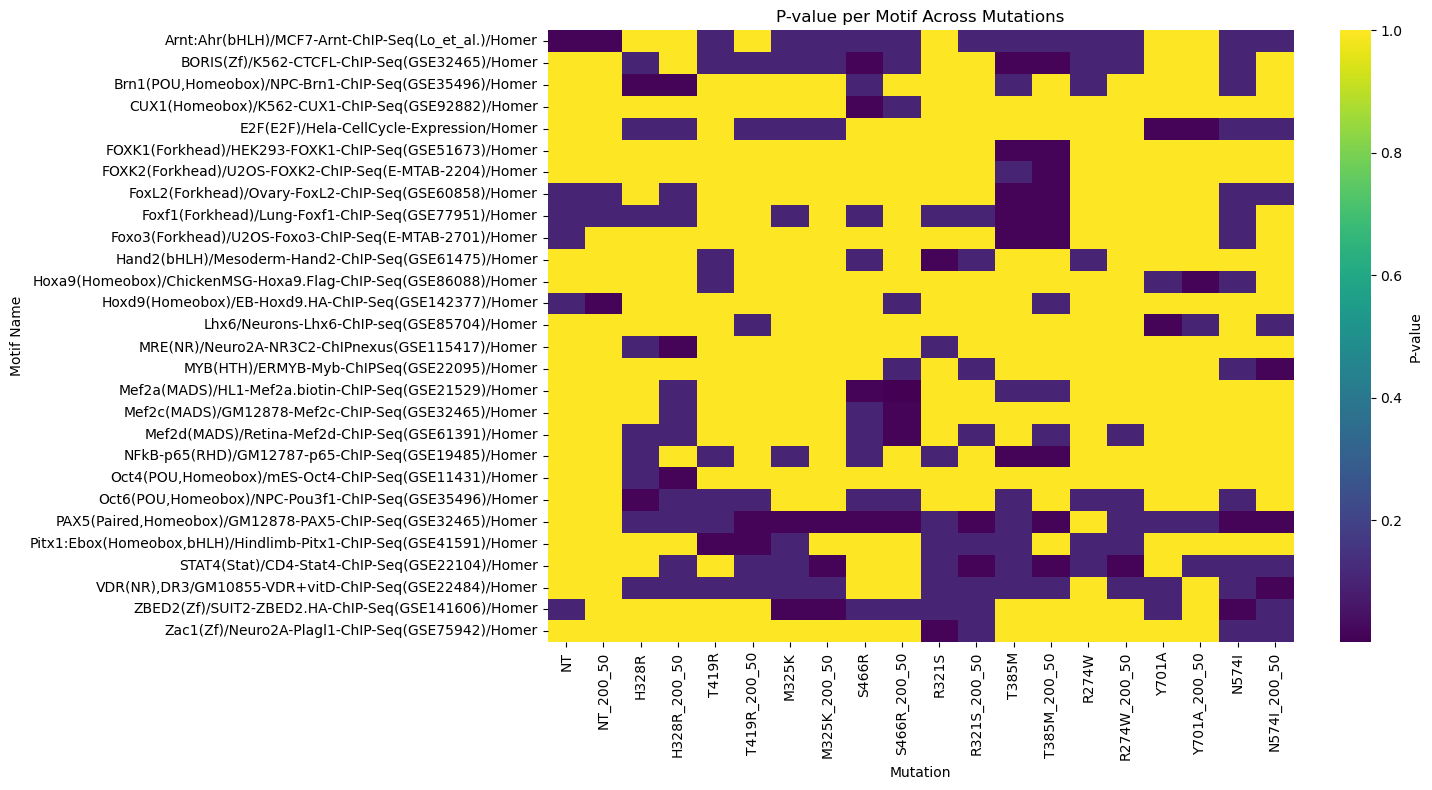

In [19]:
plt.figure(figsize=(15, 8))
sns.heatmap(df_pivot, cmap='viridis', cbar_kws={'label': 'P-value'})
plt.title('P-value per Motif Across Mutations')
plt.xlabel('Mutation')
plt.ylabel('Motif Name')
plt.tight_layout()
plt.show()

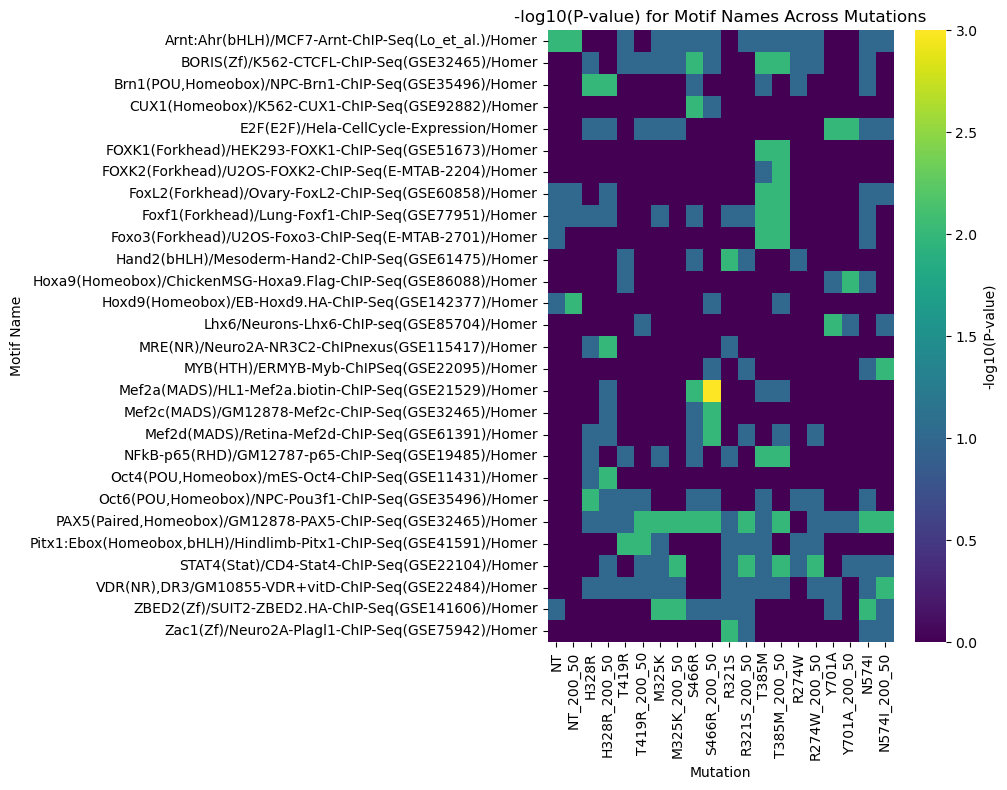

In [20]:
df_pivot_log10 = -np.log10(df_pivot)

plt.figure(figsize=(10, 8))
sns.heatmap(df_pivot_log10, cmap='viridis', cbar_kws={'label': '-log10(P-value)'})
plt.title('-log10(P-value) for Motif Names Across Mutations')
plt.xlabel('Mutation')
plt.ylabel('Motif Name')
plt.tight_layout()
plt.show()

In [21]:
df_pivot.columns

Index(['NT', 'NT_200_50', 'H328R', 'H328R_200_50', 'T419R', 'T419R_200_50',
       'M325K', 'M325K_200_50', 'S466R', 'S466R_200_50', 'R321S',
       'R321S_200_50', 'T385M', 'T385M_200_50', 'R274W', 'R274W_200_50',
       'Y701A', 'Y701A_200_50', 'N574I', 'N574I_200_50'],
      dtype='object')

In [22]:
df_pivot_bool = df_pivot.copy()
df_pivot_bool[df_pivot.columns] = np.where(df_pivot[df_pivot.columns] < 0.05, 1, 0)
df_pivot_bool.head()

,NT,NT_200_50,H328R,H328R_200_50,T419R,T419R_200_50,M325K,M325K_200_50,S466R,S466R_200_50,R321S,R321S_200_50,T385M,T385M_200_50,R274W,R274W_200_50,Y701A,Y701A_200_50,N574I,N574I_200_50
Motif Name,,,,,,,,,,,,,,,,,,,,
Arnt:Ahr(bHLH)/MCF7-Arnt-ChIP-Seq(Lo_et_al.)/Homer,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
BORIS(Zf)/K562-CTCFL-ChIP-Seq(GSE32465)/Homer,0,0,0,0,0,0,0,0,1,0,0,0,1,1,0,0,0,0,0,0
"Brn1(POU,Homeobox)/NPC-Brn1-ChIP-Seq(GSE35496)/Homer",0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
CUX1(Homeobox)/K562-CUX1-ChIP-Seq(GSE92882)/Homer,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0
E2F(E2F)/Hela-CellCycle-Expression/Homer,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0


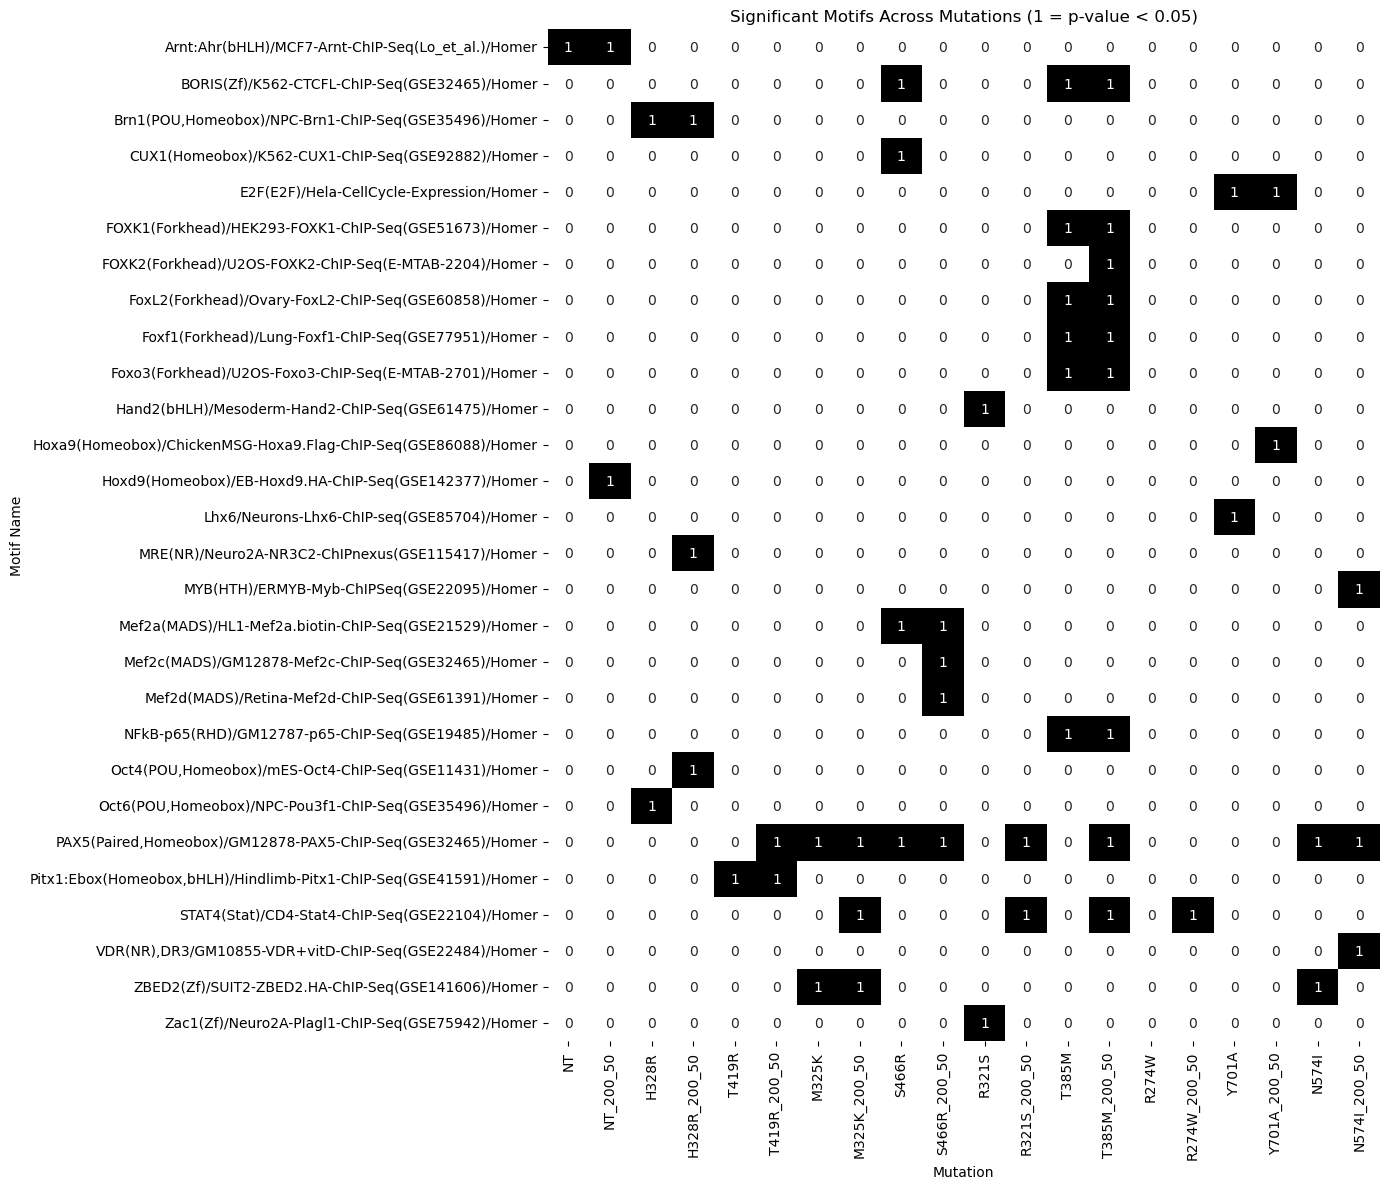

In [23]:
plt.figure(figsize=(14, 12))
sns.heatmap(df_pivot_bool, annot=True, cmap='binary', cbar=False)
plt.title('Significant Motifs Across Mutations (1 = p-value < 0.05)')
plt.xlabel('Mutation')
plt.ylabel('Motif Name')
plt.tight_layout()
plt.show()

Filter out motifs that are significant in all mutations.

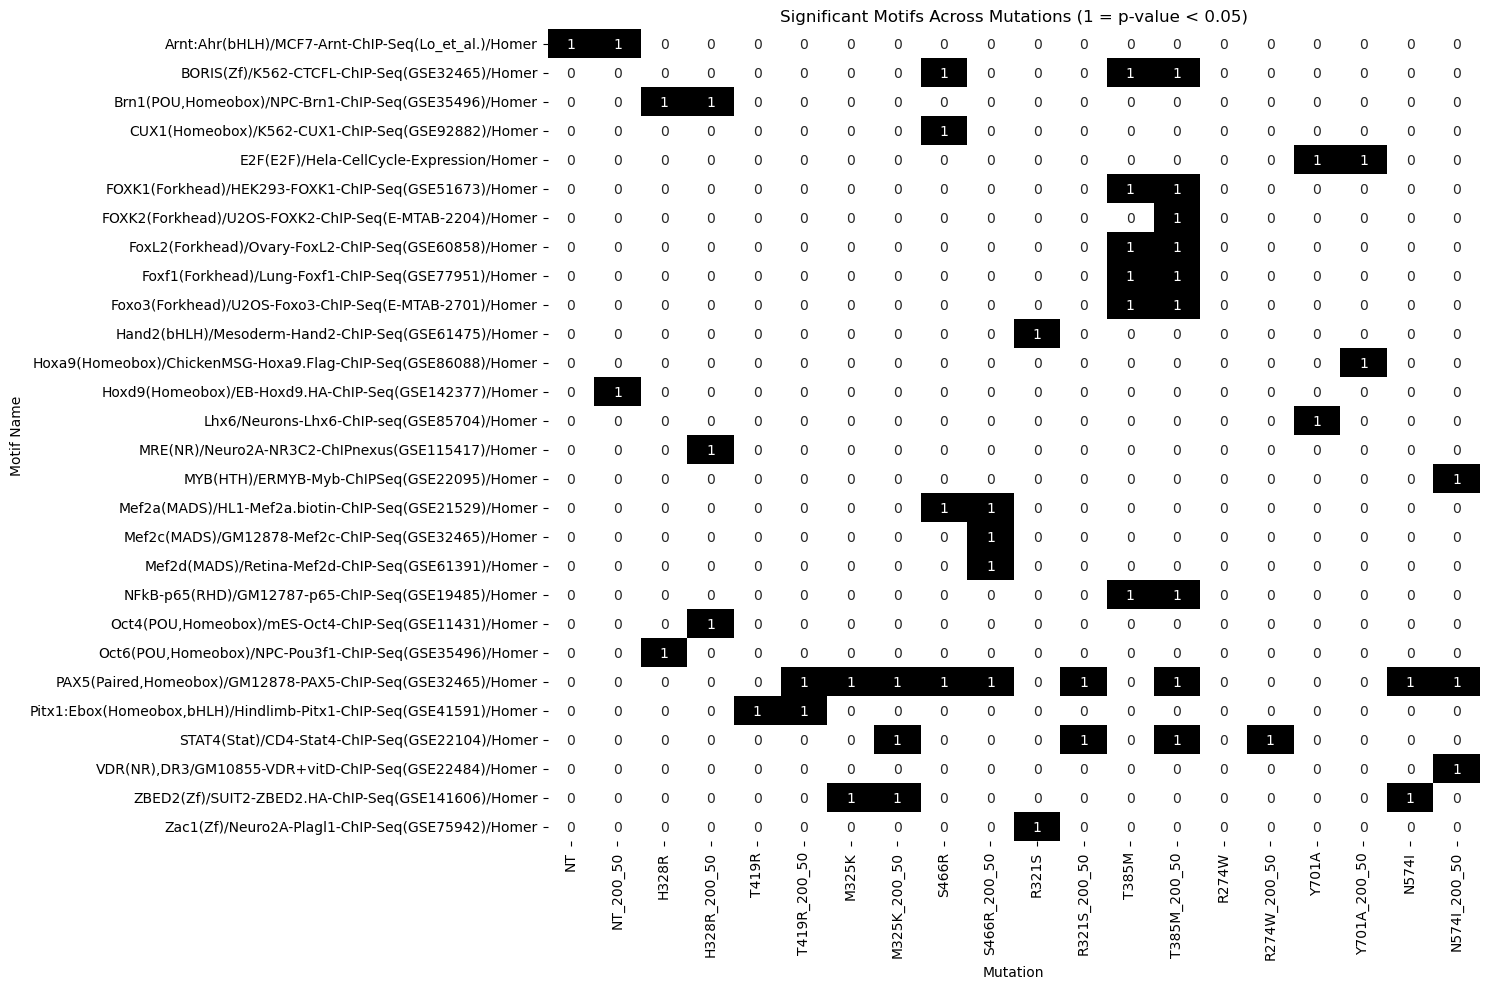

In [24]:
df_pivot_filtered = df_pivot[df_pivot[df_pivot.columns].gt(0.05).any(axis=1)]
df_pivot_bool_filtered = df_pivot_filtered.copy()
df_pivot_bool_filtered[df_pivot.columns] = np.where(df_pivot_filtered[df_pivot.columns] < 0.05, 1, 0)

plt.figure(figsize=(15, 10))
sns.heatmap(df_pivot_bool_filtered, annot=True, cmap='binary', cbar=False)
plt.title('Significant Motifs Across Mutations (1 = p-value < 0.05)')
plt.xlabel('Mutation')
plt.ylabel('Motif Name')
plt.tight_layout()
plt.show()

Applying hierarchical clustering order to both rows (as in the previous plot) and columns, and displaying the dendrogram.

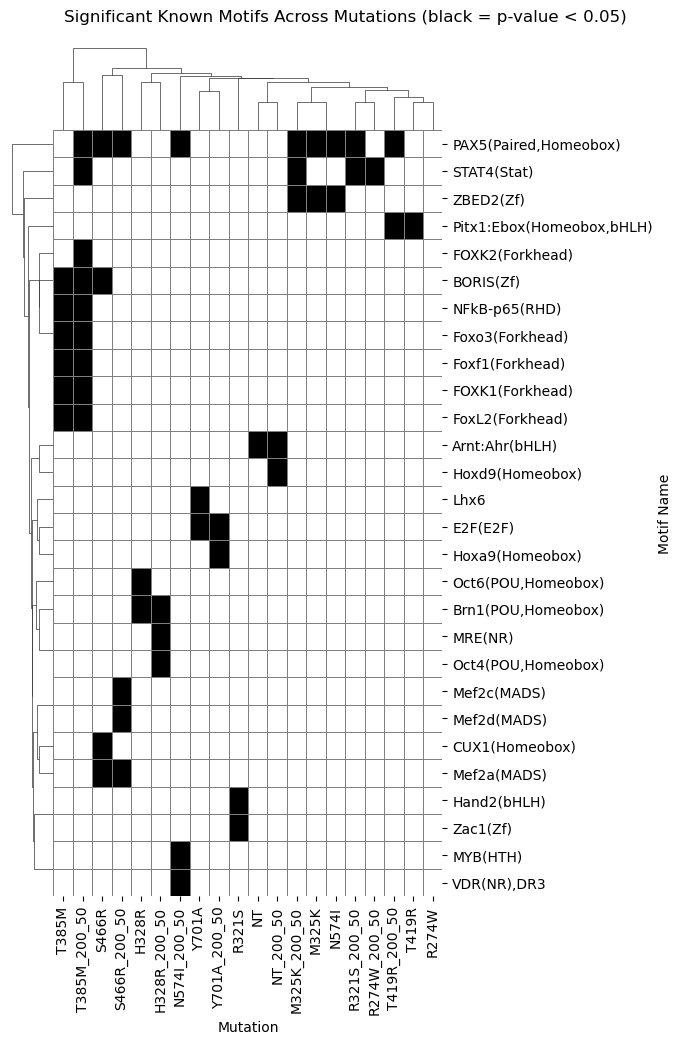

In [25]:
g = sns.clustermap(
    df_pivot_bool_filtered,
    method='average',
    metric='euclidean',
    cmap='binary',
    lw=0.5,
    linecolor="gray",
    annot=False,
    cbar=False,
    cbar_pos=None,
    dendrogram_ratio=0.1,
    figsize=(10, 10)
)

# Update motif names in the index
g.ax_heatmap.set_yticklabels([label.get_text().split("/", 1)[0] for label in g.ax_heatmap.get_yticklabels()])
g.figure.suptitle('Significant Known Motifs Across Mutations (black = p-value < 0.05)', y=1.02, x=0.35)  # Adjust y for positioning
g.ax_heatmap.set_xlabel('Mutation')
g.ax_heatmap.set_ylabel('Motif Name')

plt.show()

#### Filter by q-value

In [26]:
# Select columns: 'Motif Name' and all 'q-value' columns
qvalue_cols = [col for col in comparison.columns if col.startswith('q-value')]

# Create a DataFrame with only the relevant columns
df_qvalues = comparison[['Motif Name'] + qvalue_cols].copy()

In [27]:
df_qvalues

,Motif Name,q-value (Benjamini)_NT,q-value (Benjamini)_NT_200_50,q-value (Benjamini)_H328R,q-value (Benjamini)_H328R_200_50,q-value (Benjamini)_T419R,q-value (Benjamini)_T419R_200_50,q-value (Benjamini)_M325K,q-value (Benjamini)_M325K_200_50,q-value (Benjamini)_S466R,...,q-value (Benjamini)_R321S,q-value (Benjamini)_R321S_200_50,q-value (Benjamini)_T385M,q-value (Benjamini)_T385M_200_50,q-value (Benjamini)_R274W,q-value (Benjamini)_R274W_200_50,q-value (Benjamini)_Y701A,q-value (Benjamini)_Y701A_200_50,q-value (Benjamini)_N574I,q-value (Benjamini)_N574I_200_50
0,AMYB(HTH)/Testes-AMYB-ChIP-Seq(GSE44588)/Homer,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
1,AP-1(bZIP)/ThioMac-PU.1-ChIP-Seq(GSE21512)/Homer,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
2,AP-2alpha(AP2)/Hela-AP2alpha-ChIP-Seq(GSE31477...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
3,AP-2gamma(AP2)/MCF7-TFAP2C-ChIP-Seq(GSE21234)/...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
4,AR-halfsite(NR)/LNCaP-AR-ChIP-Seq(GSE27824)/Homer,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
466,p53(p53)/Saos-p53-ChIP-Seq(GSE15780)/Homer,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
467,p53(p53)/Saos-p53-ChIP-Seq/Homer,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
468,p53(p53)/mES-cMyc-ChIP-Seq(GSE11431)/Homer,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
469,p63(p53)/Keratinocyte-p63-ChIP-Seq(GSE17611)/H...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [28]:
# Filter for rows where any q-value column is less than or equal to 0.2
df_qvalues_filtered = df_qvalues[df_qvalues[qvalue_cols].astype(float).le(0.2).any(axis=1)]
df_qvalues_filtered.shape

(1, 21)

In [29]:
df_qvalues_filtered.columns = ['Motif Name'] + [col.replace('q-value (Benjamini)_', '') for col in df_qvalues.columns if col.startswith('q-value (Benjamini)_')]
df_qvalues_pivot = df_qvalues_filtered.set_index('Motif Name')
df_qvalues_pivot.head()

,NT,NT_200_50,H328R,H328R_200_50,T419R,T419R_200_50,M325K,M325K_200_50,S466R,S466R_200_50,R321S,R321S_200_50,T385M,T385M_200_50,R274W,R274W_200_50,Y701A,Y701A_200_50,N574I,N574I_200_50
Motif Name,,,,,,,,,,,,,,,,,,,,
Mef2a(MADS)/HL1-Mef2a.biotin-ChIP-Seq(GSE21529)/Homer,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.1981,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


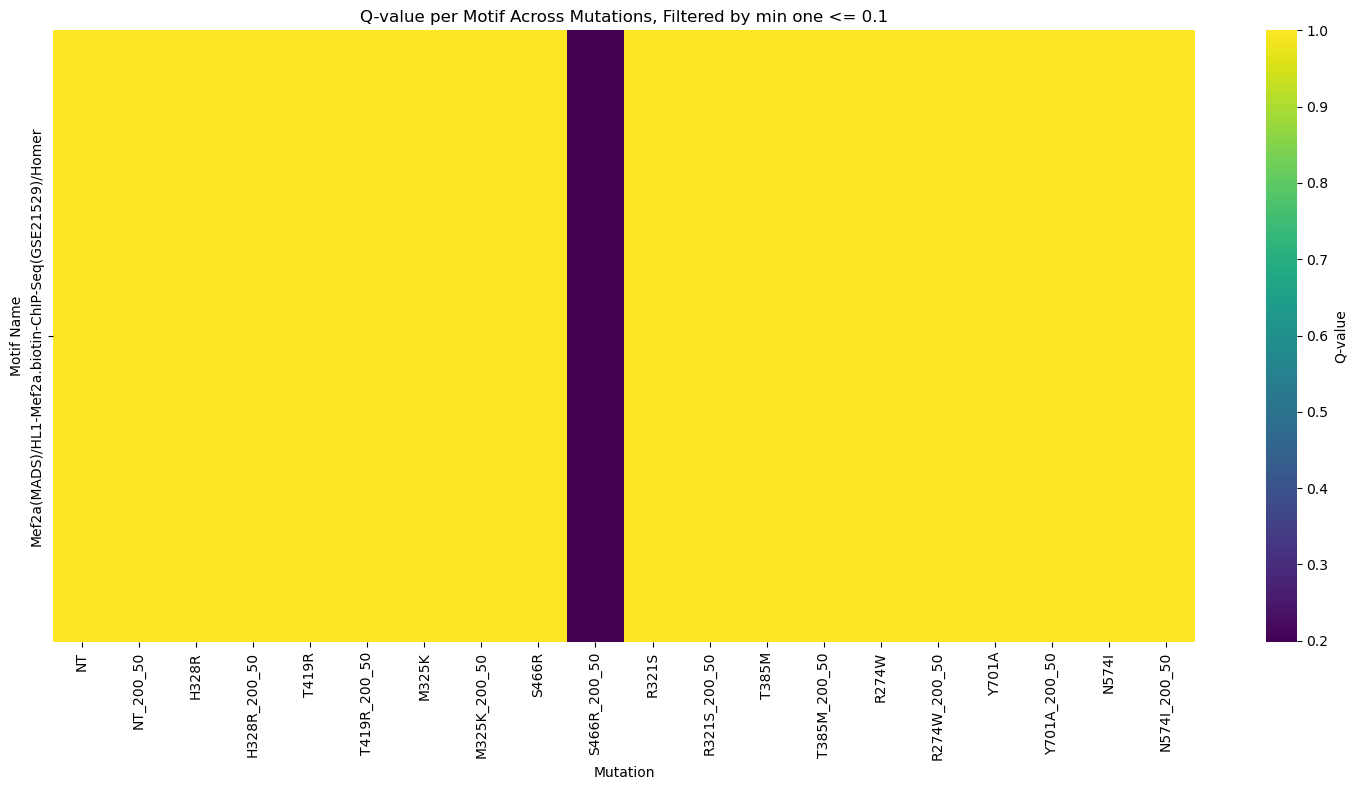

In [30]:
plt.figure(figsize=(15, 8))
sns.heatmap(df_qvalues_pivot, cmap='viridis', cbar_kws={'label': 'Q-value'})
plt.title('Q-value per Motif Across Mutations, Filtered by min one <= 0.1')
plt.xlabel('Mutation')
plt.ylabel('Motif Name')
plt.tight_layout()
plt.show()

#### Target gene %

In [31]:
comparison.columns

Index(['Motif Name', 'Consensus_NT', 'P-value_NT', 'Log P-value_NT',
       'q-value (Benjamini)_NT', '# of Target Sequences with Motif(of 13)_NT',
       '% of Target Sequences with Motif_NT',
       '# of Background Sequences with Motif(of 33290)',
       '% of Background Sequences with Motif_NT', 'Consensus_NT_200_50',
       ...
       '# of Background Sequences with Motif(of 39057)',
       '% of Background Sequences with Motif_N574I', 'Consensus_N574I_200_50',
       'P-value_N574I_200_50', 'Log P-value_N574I_200_50',
       'q-value (Benjamini)_N574I_200_50',
       '# of Target Sequences with Motif(of 13)_N574I_200_50',
       '% of Target Sequences with Motif_N574I_200_50',
       '# of Background Sequences with Motif(of 36914)',
       '% of Background Sequences with Motif_N574I_200_50'],
      dtype='object', length=161)

In [32]:
target_cols = [col for col in comparison.columns if col.startswith('% of Target Sequences with Motif_')]
df_targetpercent = comparison[['Motif Name'] + target_cols].copy()

In [33]:
df_targetpercent = df_targetpercent.map(lambda x: float(x.replace('%', '')) if isinstance(x, str) and '%' in x else x)

In [34]:
df_targetpercent.head()

,Motif Name,% of Target Sequences with Motif_NT,% of Target Sequences with Motif_NT_200_50,% of Target Sequences with Motif_H328R,% of Target Sequences with Motif_H328R_200_50,% of Target Sequences with Motif_T419R,% of Target Sequences with Motif_T419R_200_50,% of Target Sequences with Motif_M325K,% of Target Sequences with Motif_M325K_200_50,% of Target Sequences with Motif_S466R,...,% of Target Sequences with Motif_R321S,% of Target Sequences with Motif_R321S_200_50,% of Target Sequences with Motif_T385M,% of Target Sequences with Motif_T385M_200_50,% of Target Sequences with Motif_R274W,% of Target Sequences with Motif_R274W_200_50,% of Target Sequences with Motif_Y701A,% of Target Sequences with Motif_Y701A_200_50,% of Target Sequences with Motif_N574I,% of Target Sequences with Motif_N574I_200_50
0,AMYB(HTH)/Testes-AMYB-ChIP-Seq(GSE44588)/Homer,38.46,30.77,23.33,13.33,28.0,20.0,21.62,18.92,24.62,...,24.49,22.45,36.0,32.0,20.00,17.14,26.67,20.00,38.46,30.77
1,AP-1(bZIP)/ThioMac-PU.1-ChIP-Seq(GSE21512)/Homer,7.69,7.69,10.00,5.00,4.0,0.0,8.11,5.41,3.08,...,4.08,2.04,8.0,4.0,8.57,5.71,6.67,6.67,0.00,0.00
2,AP-2alpha(AP2)/Hela-AP2alpha-ChIP-Seq(GSE31477...,23.08,15.38,23.33,20.00,20.0,16.0,16.22,13.51,20.00,...,14.29,12.24,32.0,24.0,20.00,14.29,26.67,13.33,30.77,23.08
3,AP-2gamma(AP2)/MCF7-TFAP2C-ChIP-Seq(GSE21234)/...,38.46,30.77,31.67,26.67,28.0,24.0,27.03,24.32,30.77,...,22.45,18.37,40.0,32.0,34.29,25.71,40.00,33.33,53.85,46.15
4,AR-halfsite(NR)/LNCaP-AR-ChIP-Seq(GSE27824)/Homer,30.77,7.69,36.67,25.00,40.0,28.0,40.54,27.03,43.08,...,34.69,18.37,32.0,20.0,37.14,22.86,53.33,33.33,38.46,15.38


In [35]:
df_targetpercent["Motif Name"] = df_targetpercent["Motif Name"].map(lambda x: x.split("/")[:1])
df_targetpercent["Motif Name"] = df_targetpercent["Motif Name"].apply(lambda x: "/".join(map(str, x)))

In [36]:
df_targetpercent.head()

,Motif Name,% of Target Sequences with Motif_NT,% of Target Sequences with Motif_NT_200_50,% of Target Sequences with Motif_H328R,% of Target Sequences with Motif_H328R_200_50,% of Target Sequences with Motif_T419R,% of Target Sequences with Motif_T419R_200_50,% of Target Sequences with Motif_M325K,% of Target Sequences with Motif_M325K_200_50,% of Target Sequences with Motif_S466R,...,% of Target Sequences with Motif_R321S,% of Target Sequences with Motif_R321S_200_50,% of Target Sequences with Motif_T385M,% of Target Sequences with Motif_T385M_200_50,% of Target Sequences with Motif_R274W,% of Target Sequences with Motif_R274W_200_50,% of Target Sequences with Motif_Y701A,% of Target Sequences with Motif_Y701A_200_50,% of Target Sequences with Motif_N574I,% of Target Sequences with Motif_N574I_200_50
0,AMYB(HTH),38.46,30.77,23.33,13.33,28.0,20.0,21.62,18.92,24.62,...,24.49,22.45,36.0,32.0,20.00,17.14,26.67,20.00,38.46,30.77
1,AP-1(bZIP),7.69,7.69,10.00,5.00,4.0,0.0,8.11,5.41,3.08,...,4.08,2.04,8.0,4.0,8.57,5.71,6.67,6.67,0.00,0.00
2,AP-2alpha(AP2),23.08,15.38,23.33,20.00,20.0,16.0,16.22,13.51,20.00,...,14.29,12.24,32.0,24.0,20.00,14.29,26.67,13.33,30.77,23.08
3,AP-2gamma(AP2),38.46,30.77,31.67,26.67,28.0,24.0,27.03,24.32,30.77,...,22.45,18.37,40.0,32.0,34.29,25.71,40.00,33.33,53.85,46.15
4,AR-halfsite(NR),30.77,7.69,36.67,25.00,40.0,28.0,40.54,27.03,43.08,...,34.69,18.37,32.0,20.0,37.14,22.86,53.33,33.33,38.46,15.38


In [37]:
# Extract mutation names from column names
df_targetpercent.columns = ['Motif Name'] + [col.replace('% of Target Sequences with Motif_', '') for col in df_targetpercent.columns if col.startswith('% of Target Sequences with Motif_')]
df_target_pivot = df_targetpercent.set_index('Motif Name')
df_target_pivot.head()

,NT,NT_200_50,H328R,H328R_200_50,T419R,T419R_200_50,M325K,M325K_200_50,S466R,S466R_200_50,R321S,R321S_200_50,T385M,T385M_200_50,R274W,R274W_200_50,Y701A,Y701A_200_50,N574I,N574I_200_50
Motif Name,,,,,,,,,,,,,,,,,,,,
AMYB(HTH),38.46,30.77,23.33,13.33,28.0,20.0,21.62,18.92,24.62,21.54,24.49,22.45,36.0,32.0,20.00,17.14,26.67,20.00,38.46,30.77
AP-1(bZIP),7.69,7.69,10.00,5.00,4.0,0.0,8.11,5.41,3.08,1.54,4.08,2.04,8.0,4.0,8.57,5.71,6.67,6.67,0.00,0.00
AP-2alpha(AP2),23.08,15.38,23.33,20.00,20.0,16.0,16.22,13.51,20.00,16.92,14.29,12.24,32.0,24.0,20.00,14.29,26.67,13.33,30.77,23.08
AP-2gamma(AP2),38.46,30.77,31.67,26.67,28.0,24.0,27.03,24.32,30.77,26.15,22.45,18.37,40.0,32.0,34.29,25.71,40.00,33.33,53.85,46.15
AR-halfsite(NR),30.77,7.69,36.67,25.00,40.0,28.0,40.54,27.03,43.08,24.62,34.69,18.37,32.0,20.0,37.14,22.86,53.33,33.33,38.46,15.38


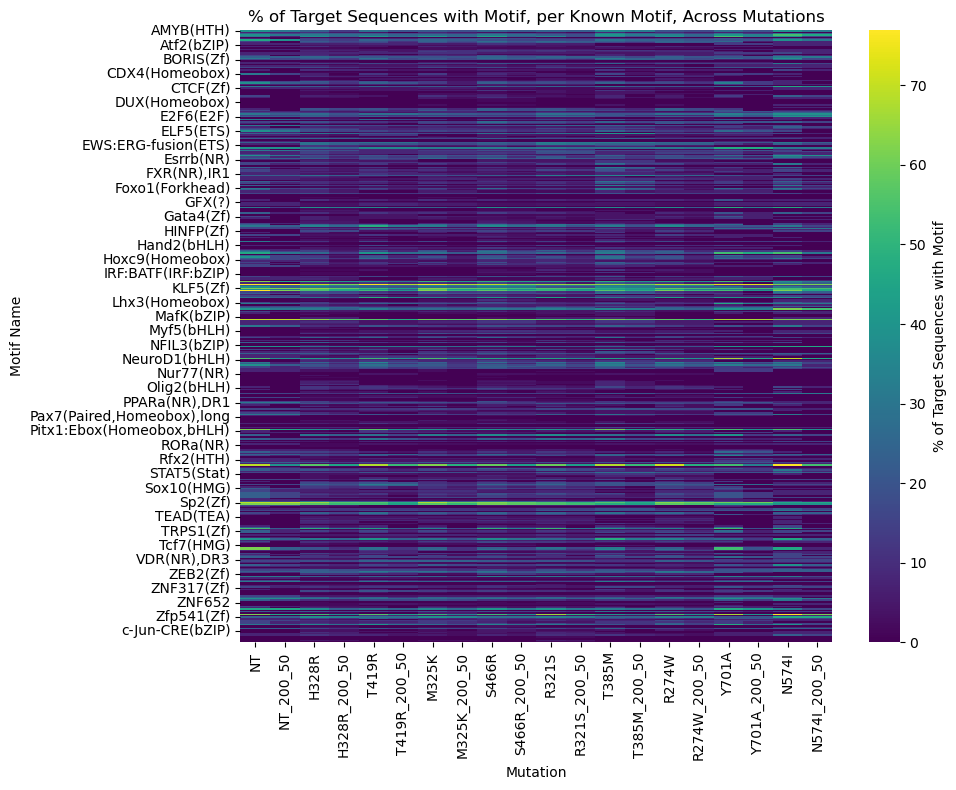

In [38]:
plt.figure(figsize=(10, 8))
sns.heatmap(df_target_pivot, cmap='viridis', cbar_kws={'label': '% of Target Sequences with Motif'})
plt.title('% of Target Sequences with Motif, per Known Motif, Across Mutations')
plt.xlabel('Mutation')
plt.ylabel('Motif Name')
plt.tight_layout()
plt.show()



In [39]:
n_motifs = df_target_pivot.shape[0]
height_per_motif = 0.25 
fig_height = max(8, n_motifs * height_per_motif)  # min height 8
fig_width = 10

g = sns.clustermap(
    df_target_pivot,
    method='average',
    metric='euclidean',
    cmap='viridis',
    cbar=True,
    cbar_pos=(0.90, 0.05, 0.03, 0.3),
    dendrogram_ratio=0.1,
    figsize=(fig_width, fig_height)
)

# Update motif names in the index
g.figure.suptitle('% of Target Sequences with Motif, per Known Motif, Across Mutations (Hierachical clustering)', y=1.02)
g.ax_heatmap.set_xlabel('Mutation')
g.ax_heatmap.set_ylabel('Motif Name')

plt.show()

**Filter by motifs with significant differences across mutations**

Show only the motifs that, as a result of the previous analysis, were found to be significant in some mutations and non-significant in others.

In [40]:
motifs_sig = df_pivot_bool_filtered.index

In [41]:
len(motifs_sig)

28

Shorten the motif names.

In [42]:
motifs_sig = motifs_sig.map(lambda x: x.split("/",1)[0])

In [43]:
motifs_sig

Index(['Arnt:Ahr(bHLH)', 'BORIS(Zf)', 'Brn1(POU,Homeobox)', 'CUX1(Homeobox)',
       'E2F(E2F)', 'FOXK1(Forkhead)', 'FOXK2(Forkhead)', 'FoxL2(Forkhead)',
       'Foxf1(Forkhead)', 'Foxo3(Forkhead)', 'Hand2(bHLH)', 'Hoxa9(Homeobox)',
       'Hoxd9(Homeobox)', 'Lhx6', 'MRE(NR)', 'MYB(HTH)', 'Mef2a(MADS)',
       'Mef2c(MADS)', 'Mef2d(MADS)', 'NFkB-p65(RHD)', 'Oct4(POU,Homeobox)',
       'Oct6(POU,Homeobox)', 'PAX5(Paired,Homeobox)',
       'Pitx1:Ebox(Homeobox,bHLH)', 'STAT4(Stat)', 'VDR(NR),DR3', 'ZBED2(Zf)',
       'Zac1(Zf)'],
      dtype='object', name='Motif Name')

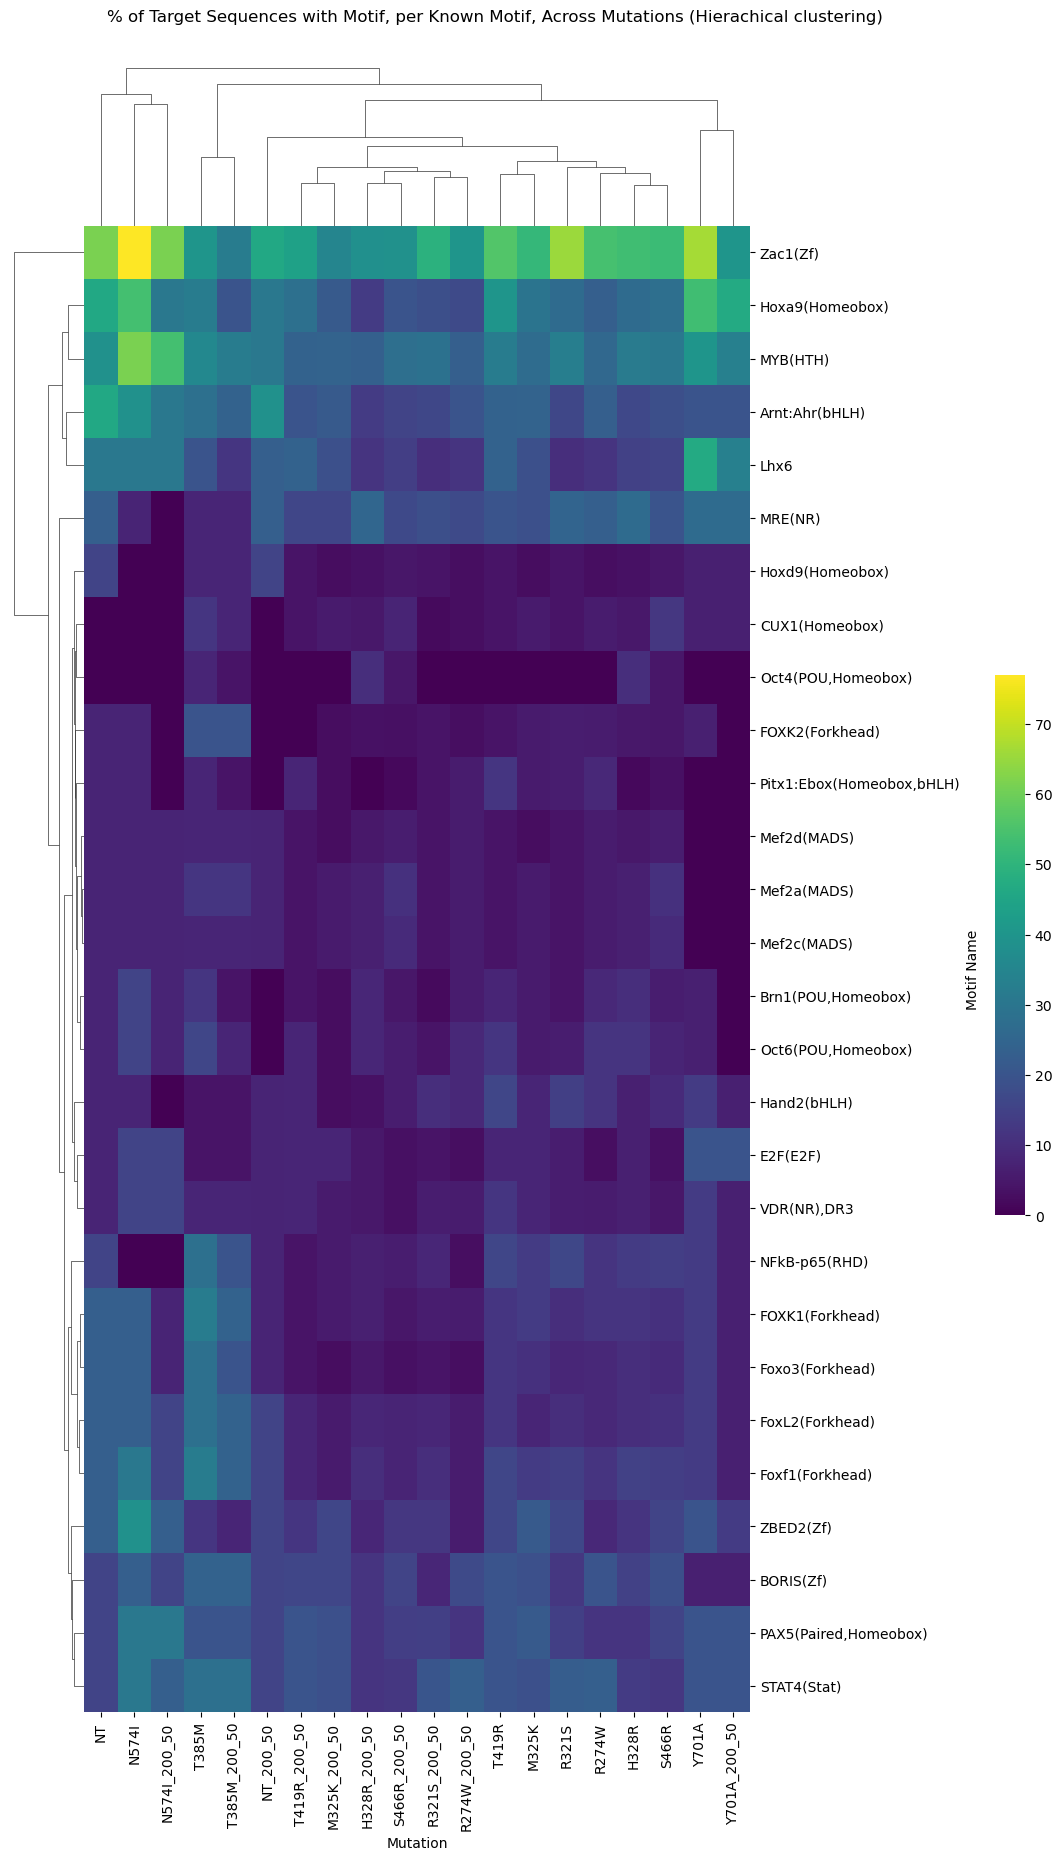

In [44]:
g = sns.clustermap(
    df_target_pivot[df_target_pivot.index.isin(motifs_sig)],
    method='average',
    metric='euclidean',
    cmap='viridis',
    cbar=True,
    cbar_pos=(1, 0.35, 0.03, 0.3),
    dendrogram_ratio=0.1,
    figsize=(10, 18)
)

# Update motif names in the index
g.figure.suptitle('% of Target Sequences with Motif, per Known Motif, Across Mutations (Hierachical clustering)', y=1.02)
g.ax_heatmap.set_xlabel('Mutation')
g.ax_heatmap.set_ylabel('Motif Name')

plt.show()

### De novo significant motifs

HOMER seems to mark as "possible false possitive" the de novo motifs with p-value <= 1e-11.

In [45]:
def parse_denovo_motifs(file_path):
    # Initialize lists to store parsed data
    data = {
        'Consensus': [],
        'Motif_Name': [],
        'Best_Guess': [],
        'Score': [],
        'Log_Pvalue': [],
        'Qvalue': [],
        'Target_Percent': [],
        'Background_Percent': [],
        'Pvalue': []
    }
    
    # Read the file
    with open(file_path, 'r') as f:
        for line in f:
            if line.startswith('>'):
                # Split the header line
                parts = line.strip().split('\t')
                if len(parts) < 6:
                    continue  # Skip malformed lines
                
                # Extract fields
                consensus = parts[0][1:]  # Remove '>'
                motif_info = parts[1].split(',')
                motif_name = motif_info[0]
                best_guess = motif_info[1].replace("BestGuess:", "") if len(motif_info) > 1 else 'Unknown'
                score = float(parts[2])
                log_pvalue = float(parts[3])
                qvalue = float(parts[4])
                
                # Parse target and background stats
                stats = parts[5].split(',')
                target_info = stats[0].split(':')[1].split('(')
                target_count = float(target_info[0])
                target_percent = float(target_info[1].rstrip('%)'))
                bg_info = stats[1].split(':')[1].split('(')
                bg_count = float(bg_info[0])
                bg_percent = float(bg_info[1].rstrip('%)'))
                pvalue = parts[5].split('P:')[1]
                
                # Append to data
                data['Consensus'].append(consensus)
                data['Motif_Name'].append(motif_name)
                data['Best_Guess'].append(best_guess)
                data['Score'].append(score)
                data['Log_Pvalue'].append(log_pvalue)
                data['Qvalue'].append(qvalue)
                data['Target_Percent'].append(target_percent)
                data['Background_Percent'].append(bg_percent)
                data['Pvalue'].append(pvalue)
    
    # Create DataFrame
    df = pd.DataFrame(data)
    return df

In [46]:
novo_motif_dfs = {}

for col in cols:
    key_motifs = f"{col}_motifs"
    key_motifs_200_50 = f"{col}_motifs_200_50"

    print(key_motifs)
    novo_motif_dfs[key_motifs] = parse_denovo_motifs(f"up_IFNg_vs_WT_IFNg/up_{col}/nonRedundant.motifs")
    print(novo_motif_dfs[key_motifs].shape)
    
    print(key_motifs_200_50)
    novo_motif_dfs[key_motifs_200_50] = parse_denovo_motifs(f"up_IFNg_vs_WT_IFNg/up_{col}_200_50/nonRedundant.motifs")
    print(novo_motif_dfs[key_motifs_200_50].shape)

NT_motifs
(43, 9)
NT_motifs_200_50
(45, 9)
H328R_motifs
(13, 9)
H328R_motifs_200_50
(12, 9)
T419R_motifs
(15, 9)
T419R_motifs_200_50
(14, 9)
M325K_motifs
(13, 9)
M325K_motifs_200_50
(13, 9)
S466R_motifs
(13, 9)
S466R_motifs_200_50
(13, 9)
R321S_motifs
(15, 9)
R321S_motifs_200_50
(11, 9)
T385M_motifs
(14, 9)
T385M_motifs_200_50
(12, 9)
R274W_motifs
(12, 9)
R274W_motifs_200_50
(9, 9)
Y701A_motifs
(44, 9)
Y701A_motifs_200_50
(39, 9)
N574I_motifs
(44, 9)
N574I_motifs_200_50
(44, 9)


In [47]:
df_pivot.columns

Index(['NT', 'NT_200_50', 'H328R', 'H328R_200_50', 'T419R', 'T419R_200_50',
       'M325K', 'M325K_200_50', 'S466R', 'S466R_200_50', 'R321S',
       'R321S_200_50', 'T385M', 'T385M_200_50', 'R274W', 'R274W_200_50',
       'Y701A', 'Y701A_200_50', 'N574I', 'N574I_200_50'],
      dtype='object')

In [48]:
# Initialize an empty list to collect data
motif_pvalues = []

# Get unique motifs and collect P-values
for df_name in novo_motif_dfs.keys():
    # Convert Pvalue to numeric
    novo_motif_dfs[df_name]["Pvalue"] = pd.to_numeric(novo_motif_dfs[df_name]["Pvalue"])
    # Ensure the column contains only strings before applying .str
    novo_motif_dfs[df_name]["Best_Guess"] = novo_motif_dfs[df_name]["Best_Guess"].str.split("/").str[:2]
    novo_motif_dfs[df_name]["Best_Guess"] = novo_motif_dfs[df_name]["Best_Guess"].apply(lambda x: "/".join(map(str, x)))
    
    # Filter for significant motifs (P-value < 1e-11)
    filtered_df = novo_motif_dfs[df_name][["Best_Guess", "Pvalue"]].drop_duplicates()
    # Rename Pvalue column to the DataFrame name
    filtered_df = filtered_df.rename(columns={"Pvalue": df_name})
    filtered_df.columns = filtered_df.columns.str.replace('_motifs', '')
    
    # Append to list
    motif_pvalues.append(filtered_df)

# Merge all DataFrames on Best_Guess using outer join
denovo_sig = motif_pvalues[0]
for df in motif_pvalues[1:]:
    denovo_sig = denovo_sig.merge(df, on="Best_Guess", how="outer")

# Set Best_Guess as index
denovo_sig = denovo_sig.set_index("Best_Guess")

denovo_sig.shape



(293, 20)

In [49]:
denovo_sig.head(20)

,NT,NT_200_50,H328R,H328R_200_50,T419R,T419R_200_50,M325K,M325K_200_50,S466R,S466R_200_50,R321S,R321S_200_50,T385M,T385M_200_50,R274W,R274W_200_50,Y701A,Y701A_200_50,N574I,N574I_200_50
Best_Guess,,,,,,,,,,,,,,,,,,,,
ASCL1/MA1631.2,NaN,NaN,NaN,NaN,NaN,NaN,0.0010,0.001,NaN,NaN,NaN,NaN,NaN,NaN,0.001,NaN,NaN,NaN,NaN,NaN
Ahr::Arnt/MA0006.2,0.010,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.001,0.001
Ap4(bHLH)/AML-Tfap4-ChIP-Seq(GSE45738),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00100,NaN,NaN
Arid3a/MA0151.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Arnt:Ahr(bHLH)/MCF7-Arnt-ChIP-Seq(Lo_et_al.),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.001
Atf3/MA1988.2,0.001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.001,NaN,NaN,NaN
Atoh1/MA0461.3,NaN,NaN,0.001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00100,NaN,NaN
BATF3/MA0835.3,NaN,0.001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00100,NaN,NaN
BCL6/MA0463.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000e-08,NaN,NaN,NaN,NaN


In [50]:
denovo_sig['N574I'].head(20)

Best_Guess
ASCL1/MA1631.2                                                   NaN
Ahr::Arnt/MA0006.2                                             0.001
Ap4(bHLH)/AML-Tfap4-ChIP-Seq(GSE45738)                           NaN
Arid3a/MA0151.1                                                  NaN
Arnt:Ahr(bHLH)/MCF7-Arnt-ChIP-Seq(Lo_et_al.)                     NaN
Atf3/MA1988.2                                                    NaN
Atoh1/MA0461.3                                                   NaN
BATF3/MA0835.3                                                   NaN
BCL6/MA0463.3                                                    NaN
Bapx1(Homeobox)/VertebralCol-Bapx1-ChIP-Seq(GSE36672)            NaN
Bcl11B/MA1989.2                                                  NaN
Bcl6(Zf)/Liver-Bcl6-ChIP-Seq(GSE31578)                           NaN
CDX2/MA0465.3                                                    NaN
CDX4(Homeobox)/ZebrafishEmbryos-Cdx4.Myc-ChIP-Seq(GSE48254)      NaN
CEBP:AP1(bZIP)/ThioMac-

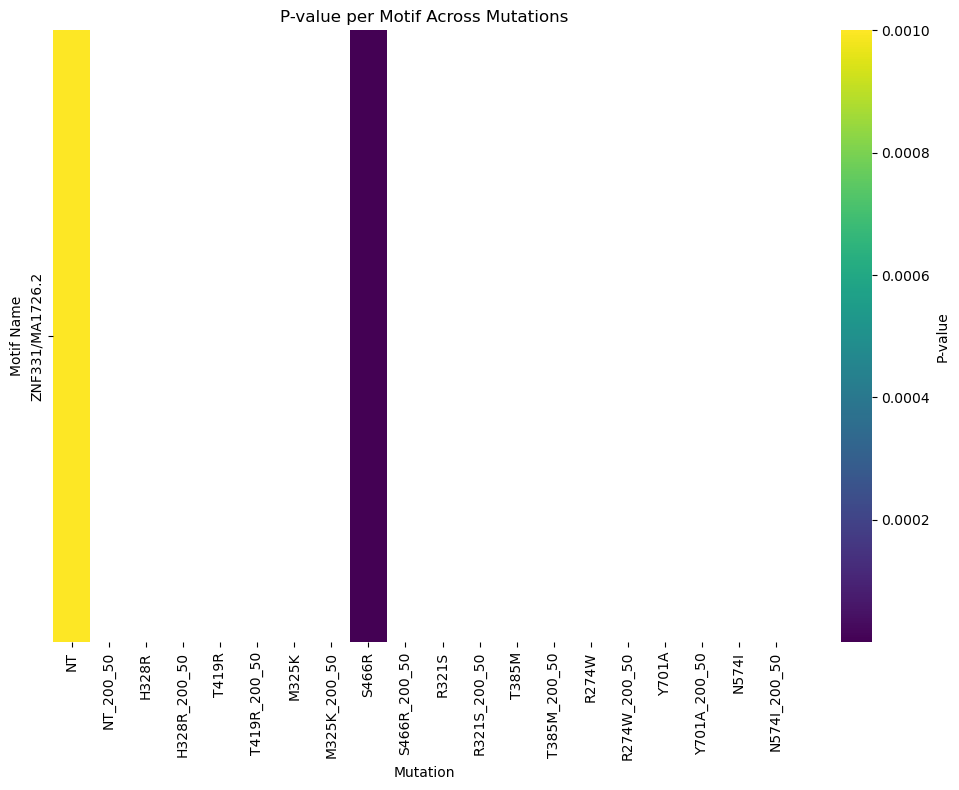

In [51]:
denovo_sig_filtered = denovo_sig[denovo_sig[denovo_sig.columns].le(1e-11).any(axis=1)]


plt.figure(figsize=(10, 8))
sns.heatmap(denovo_sig_filtered, cmap='viridis', cbar_kws={'label': 'P-value'})
plt.title('P-value per Motif Across Mutations')
plt.xlabel('Mutation')
plt.ylabel('Motif Name')
plt.tight_layout()
plt.show()

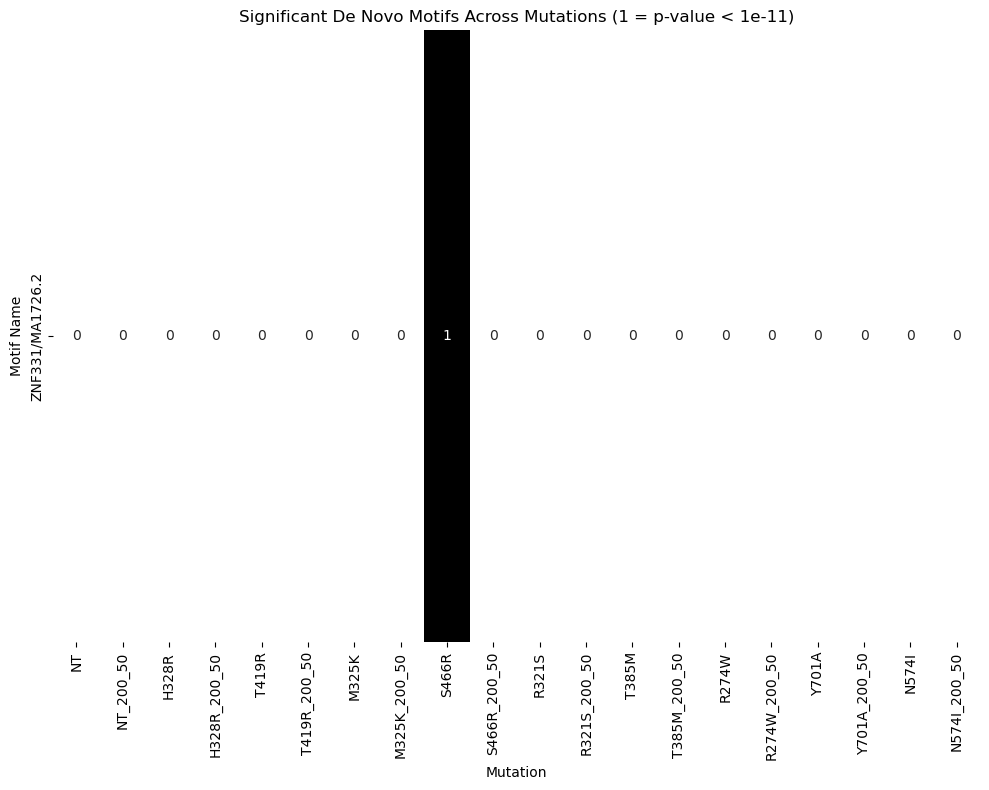

In [52]:
denovo_sig_filtered_bool = denovo_sig_filtered.copy()
denovo_sig_filtered_bool[df_pivot.columns] = np.where(denovo_sig_filtered[df_pivot.columns] <= 1e-11, 1, 0)

plt.figure(figsize=(10, 8))
sns.heatmap(denovo_sig_filtered_bool, annot=True, cmap='binary', cbar=False)
plt.title('Significant De Novo Motifs Across Mutations (1 = p-value < 1e-11)')
plt.xlabel('Mutation')
plt.ylabel('Motif Name')
plt.tight_layout()
plt.show()

#### Matches and scores

In [53]:
from bs4 import BeautifulSoup
import re
import glob

In [54]:
# Function to extract score and offset from text
def extract_score_offset(text):
    score = None
    offset = None
    try:
        # Match Score: followed by a number (int or float)
        score_match = re.search(r'Score:\s*([\d.]+)', text)
        if score_match:
            score_str = score_match.group(1)
            score = float(score_str)  
        # Match Offset: followed by an integer (positive or negative)
        offset_match = re.search(r'Offset:\s*([-]?\d+)', text)
        if offset_match:
            offset = int(offset_match.group(1))
    except (ValueError, TypeError) as e:
        print(f"Error parsing text: {text}, Error: {e}")
    return score, offset

# Base directory containing mutation subfolders
base_dir = 'up_IFNg_vs_WT_IFNg'

# Initialize lists to store data
all_motif_names = []
all_scores = []
all_offsets = []
all_motif_numbers = []
all_mutations = []

# Find all subfolders matching up_* (only directories)
mutation_folders = [f for f in glob.glob(os.path.join(base_dir, 'up_*')) if os.path.isdir(f)]
if not mutation_folders:
    print(f"No mutation folders found in {base_dir}")
    exit(1)

for mut_folder in mutation_folders:
    # Extract mutation name from folder (e.g., up_WT -> WT)
    mut_name = os.path.basename(mut_folder).replace('up_', '')
    
    # Path to homerResults directory
    homer_dir = os.path.join(mut_folder, 'homerResults')
    
    # Find all motif*.info.html files in homerResults
    file_pattern = os.path.join(homer_dir, 'motif*.info.html')
    html_files = glob.glob(file_pattern)
    
    if not html_files:
        print(f"No motif files found in {homer_dir}")
        continue
    
    for file_path in html_files:
        # Extract motif number from filename (e.g., motif1.info.html -> 1)
        filename = os.path.basename(file_path)
        motif_number_match = re.search(r'motif(\d+)\.info\.html', filename)
        if motif_number_match:
            motif_number = int(motif_number_match.group(1))
        else:
            print(f"Could not extract motif number from {filename}, skipping.")
            continue
        
        # Read the HTML file
        if not os.path.exists(file_path):
            print(f"File {file_path} not found, skipping.")
            continue
        
        with open(file_path, 'r') as file:
            html_content = file.read()
        
        # Parse the HTML
        soup = BeautifulSoup(html_content, 'html.parser')
        
        # Find the first occurrence of <H3>Matches to Known Motifs</H3>
        matches_section = soup.find('h3', string='Matches to Known Motifs')
        
        if matches_section:
            # Find all <H4> tags containing motif names after the Matches section
            motif_headers = matches_section.find_all_next('h4')
            
            for header in motif_headers:
                # Extract motif name from <H4> tag
                motif_name = header.text.strip()
                
                # Find the next table containing Match Rank, Score, Offset, etc.
                table = header.find_next('table')
                if table:
                    # Try to find the cell containing Score and Offset
                    cells = table.find_all('td')
                    for cell in cells:
                        cell_text = cell.text.strip()
                        score, offset = extract_score_offset(cell_text)
                        if score is not None and offset is not None:
                            all_motif_names.append(motif_name)
                            all_scores.append(score)
                            all_offsets.append(offset)
                            all_motif_numbers.append(motif_number)
                            all_mutations.append(mut_name)
                            break  # Move to next motif after finding valid data
        else:
            print(f"No 'Matches to Known Motifs' section found in {filename}")

# Create DataFrame
df_denovo = pd.DataFrame({
    'Mutation': all_mutations,
    'Motif Number': all_motif_numbers,
    'Motif Name': all_motif_names,
    'Score': all_scores,
    'Offset': all_offsets
})

In [55]:
df_denovo.sort_values('Score', ascending=False)

,Mutation,Motif Number,Motif Name,Score,Offset
4160,H328R_200_50,9,ZNF175/MA2332.1/Jaspar,0.94,-1
4161,H328R_200_50,9,ETV1/MA0761.3/Jaspar,0.94,-1
4162,H328R_200_50,9,Ets1-distal(ETS)/CD4+-PolII-ChIP-Seq(Barski_et...,0.93,-1
4163,H328R_200_50,9,Erg/MA0474.4/Jaspar,0.92,-2
3930,R274W_200_50,9,ZNF384/MA1125.2/Jaspar,0.92,0
...,...,...,...,...,...
769,N574I_200_50,1,Zic2/MA1629.2/Jaspar,0.50,1
3809,S466R_200_50,4,Elf5/MA0136.4/Jaspar,0.50,-3
3808,S466R_200_50,4,SP5/MA1965.2/Jaspar,0.50,-2
3807,S466R_200_50,4,POL009.1_DCE_S_II/Jaspar,0.50,6


Non-finite values detected in pivot_df. Filling NaN with 0.


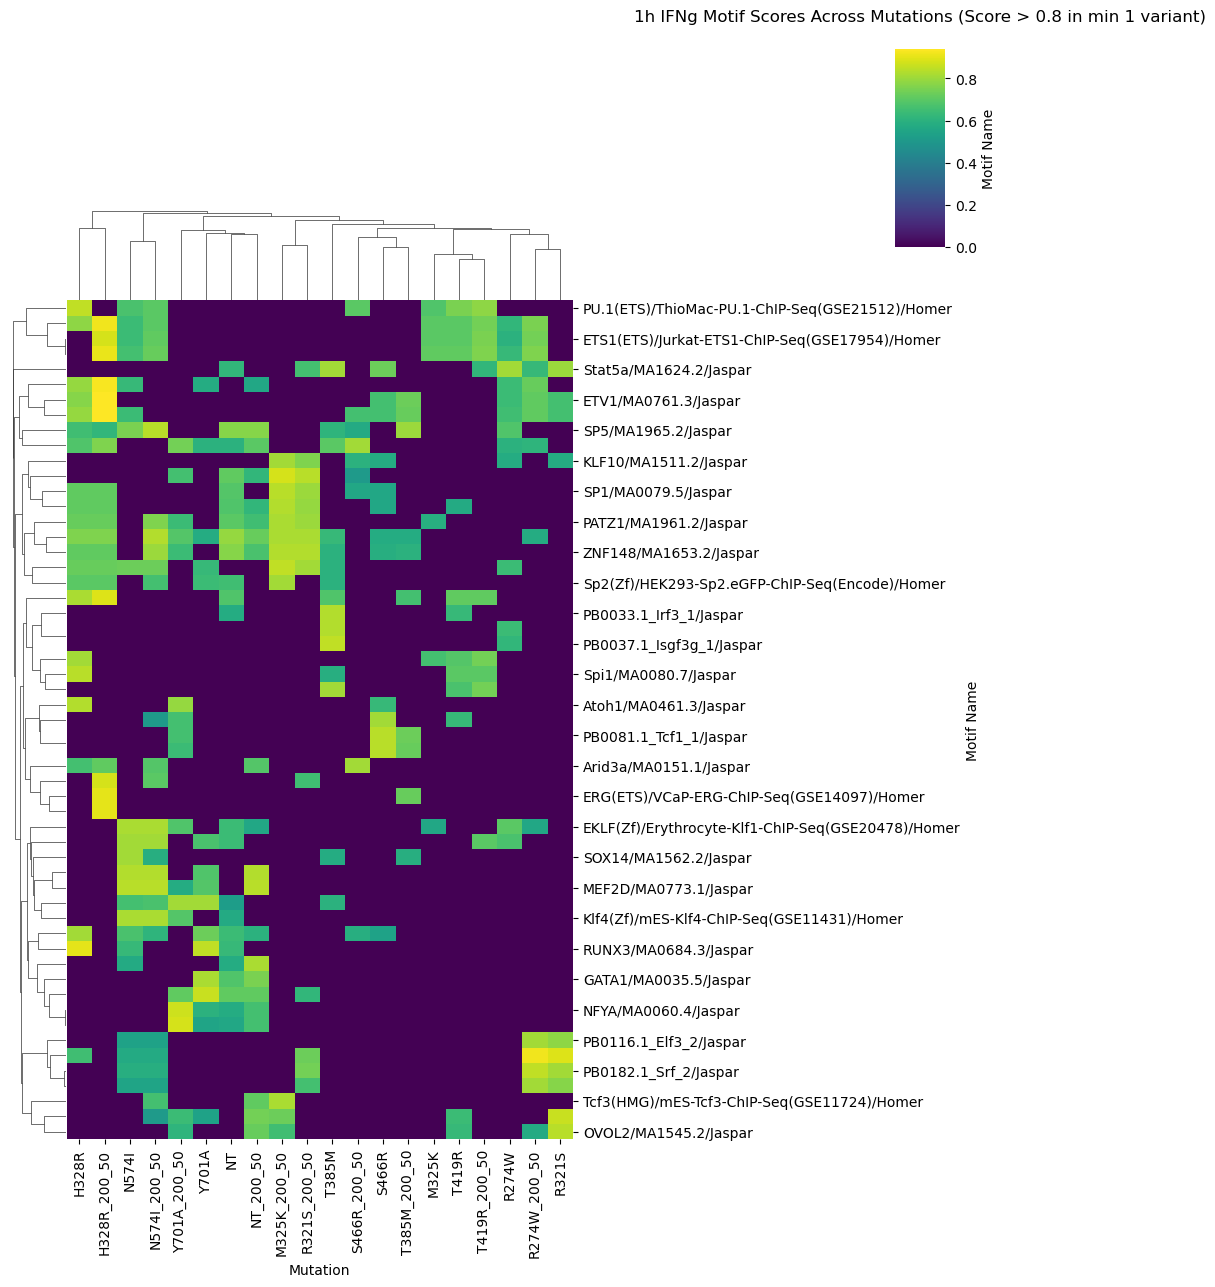

In [56]:
pivot_df = df_denovo.pivot_table(
    values='Score',
    index='Motif Name',
    columns='Mutation',
    aggfunc='max'  # Use max score for duplicates
)

pivot_df = pivot_df[pivot_df.max(axis=1) > 0.8]

# Check for non-finite values (NaN or inf)
if not pivot_df.apply(lambda x: np.isfinite(x)).all().all():
    print("Non-finite values detected in pivot_df. Filling NaN with 0.")
    pivot_df = pivot_df.fillna(0)  # Replace NaN with 0
    # Check for infinite values
    if not pivot_df.apply(lambda x: np.isfinite(x)).all().all():
        print("Infinite values detected in pivot_df. Problematic rows:")
        print(pivot_df[~pivot_df.apply(lambda x: np.isfinite(x)).all(axis=1)])
        exit(1)

# Generate clustermap with hierarchical clustering
g= sns.clustermap(
    pivot_df,
    cmap='viridis',  # Color map for scores
    cbar_kws={'label': 'Score'},  # Colorbar label
    dendrogram_ratio=0.1,  # Size of dendrograms
    figsize=(10, max(10, len(pivot_df) * 0.2)),  # Scale height with number of motifs
    cbar_pos=(0.9, 0.95, 0.05, 0.18)  # Position of colorbar
)

# Customize plot
plt.title('1h IFNg Motif Scores Across Mutations (Score > 0.8 in min 1 variant)', pad=20)
plt.ylabel('Motif Name')
plt.setp(g.ax_heatmap.get_xticklabels(), rotation=90, ha='center')

plt.show()


Filter by motifs close to STAT, that is, de novo motifs that include a STAT in their list of matches.

In [57]:
df_denovo.shape

(4380, 5)

In [58]:
df_denovo[df_denovo['Motif Name'].str.contains('STAT|stat', case=False, na=False)]

,Mutation,Motif Number,Motif Name,Score,Offset
133,T419R_200_50,6,Stat5a/MA1624.2/Jaspar,0.62,1
200,R321S,8,Stat5a/MA1624.2/Jaspar,0.80,1
201,R321S,8,Stat5a::Stat5b/MA0519.2/Jaspar,0.75,1
202,R321S,8,STAT3/MA0144.3/Jaspar,0.72,1
203,R321S,8,Stat5b/MA1625.2/Jaspar,0.71,1
...,...,...,...,...,...
3941,R274W_200_50,1,STAT3/MA0144.3/Jaspar,0.69,0
3944,R274W_200_50,1,Stat5a/MA1624.2/Jaspar,0.63,0
3947,R274W_200_50,1,Stat5a::Stat5b/MA0519.2/Jaspar,0.61,0
3948,R274W_200_50,1,Stat5b/MA1625.2/Jaspar,0.60,0


In [59]:
df_denovo[df_denovo['Motif Name'].str.contains('STAT', case=False, na=False)]['Motif Number'].unique()

array([ 6,  8,  2,  7,  9, 11, 37,  4,  1, 12,  5, 42, 26, 10])

In [60]:
df_denovo[df_denovo['Motif Name'].str.contains('STAT', case=False, na=False)][['Motif Number', 'Mutation']].drop_duplicates().values

array([[6, 'T419R_200_50'],
       [8, 'R321S'],
       [2, 'R321S'],
       [7, 'M325K'],
       [9, 'R321S_200_50'],
       [11, 'R321S_200_50'],
       [7, 'R321S_200_50'],
       [37, 'N574I_200_50'],
       [4, 'N574I_200_50'],
       [1, 'R274W'],
       [12, 'R274W'],
       [7, 'S466R'],
       [6, 'S466R'],
       [4, 'T385M'],
       [9, 'T385M'],
       [5, 'T385M'],
       [12, 'Y701A'],
       [37, 'NT'],
       [42, 'NT'],
       [26, 'NT'],
       [10, 'S466R_200_50'],
       [8, 'S466R_200_50'],
       [1, 'R274W_200_50'],
       [6, 'R274W_200_50']], dtype=object)

Non-finite values detected in pivot_df. Filling NaN with 0.


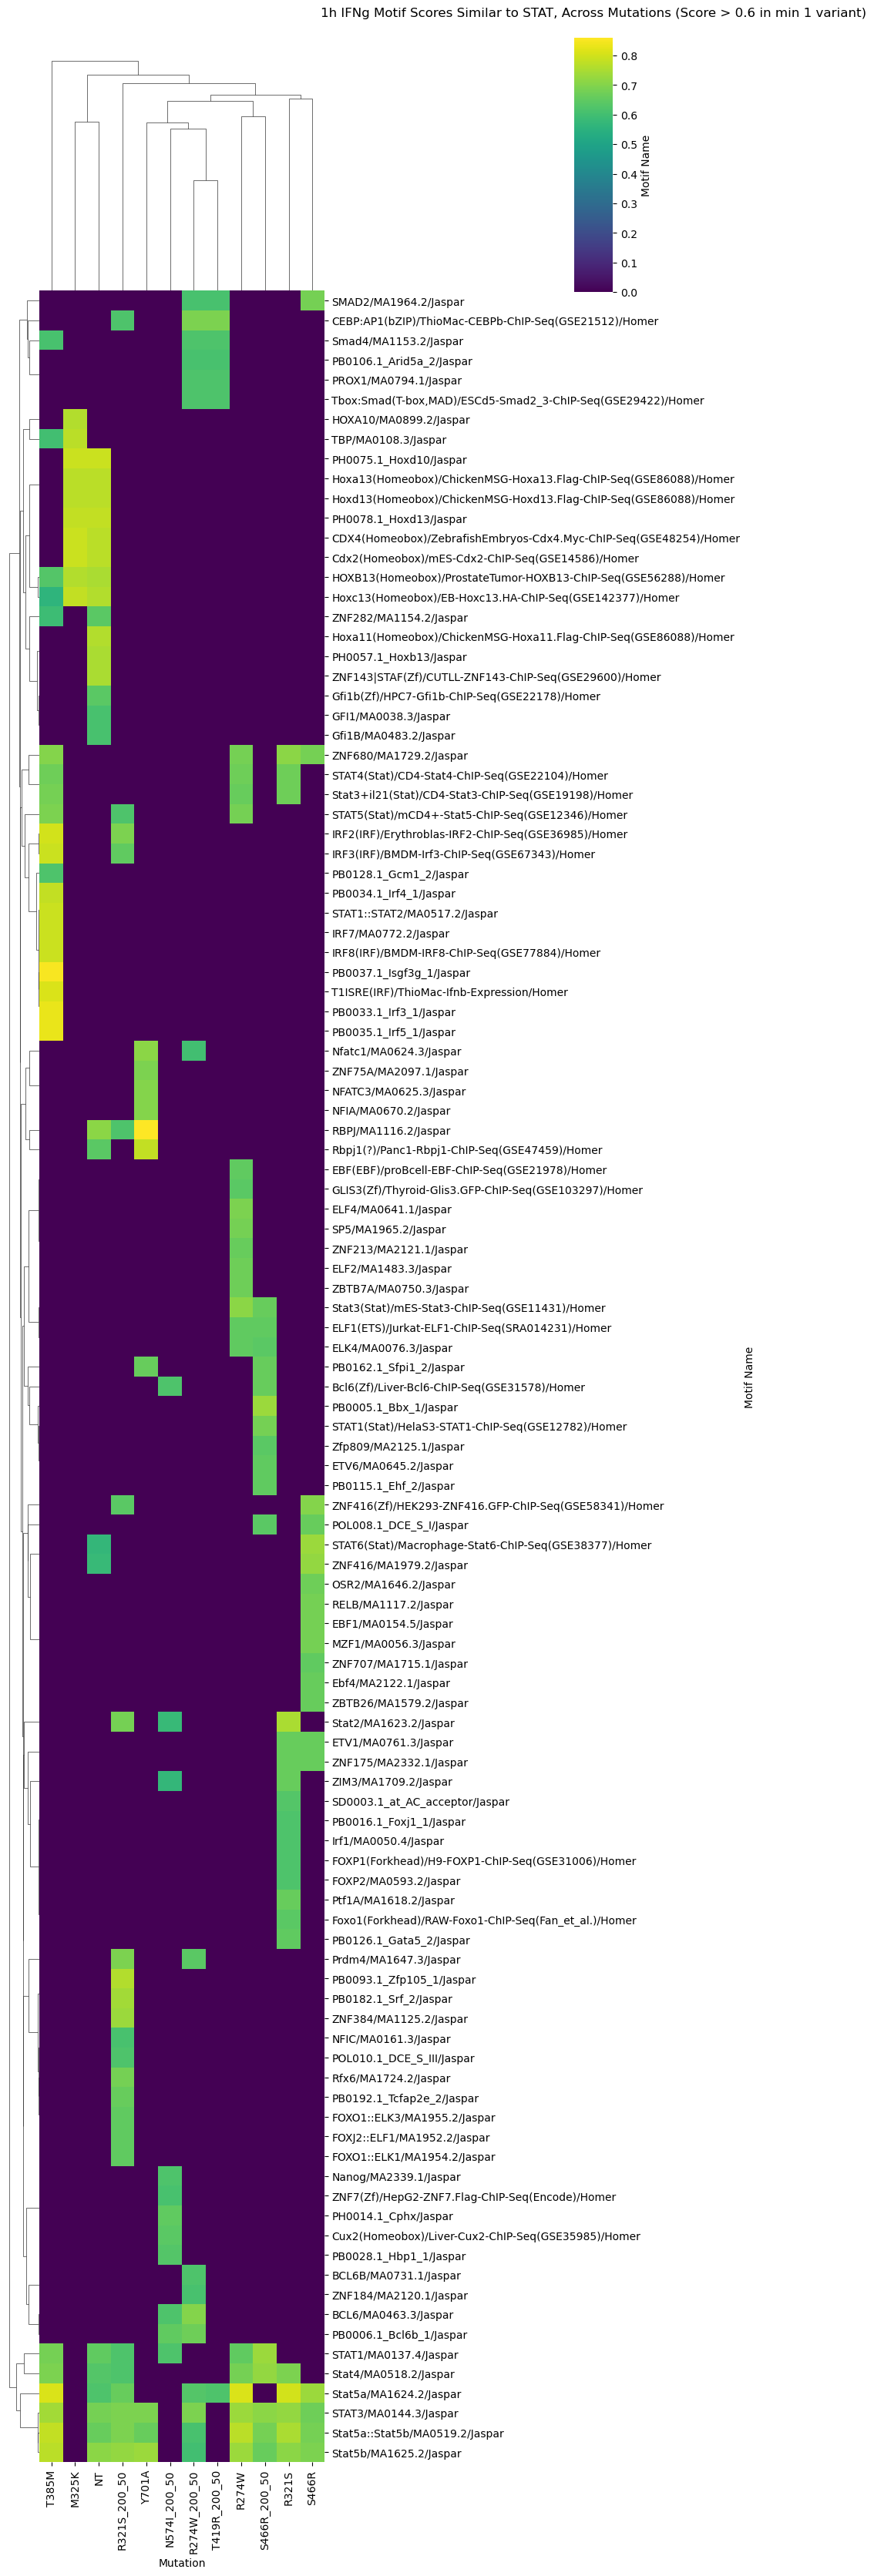

In [61]:
# Get unique Motif Number and Mutation combinations for STAT motifs
unique_combinations = df_denovo[df_denovo['Motif Name'].str.contains('STAT', case=False, na=False)][['Motif Number', 'Mutation']].drop_duplicates()

# Filter df_denovo to include only rows matching unique_combinations
df_filtered = df_denovo[df_denovo.set_index(['Motif Number', 'Mutation']).index.isin(unique_combinations.set_index(['Motif Number', 'Mutation']).index)]

pivot_df = df_filtered.pivot_table(
    values='Score',
    index='Motif Name',
    columns='Mutation',
    aggfunc='max'  # Use max score for duplicates
)

pivot_df = pivot_df[pivot_df.max(axis=1) > 0.6]

# Check for non-finite values (NaN or inf)
if not pivot_df.apply(lambda x: np.isfinite(x)).all().all():
    print("Non-finite values detected in pivot_df. Filling NaN with 0.")
    pivot_df = pivot_df.fillna(0)  # Replace NaN with 0
    # Check for infinite values
    if not pivot_df.apply(lambda x: np.isfinite(x)).all().all():
        print("Infinite values detected in pivot_df. Problematic rows:")
        print(pivot_df[~pivot_df.apply(lambda x: np.isfinite(x)).all(axis=1)])
        exit(1)

# Generate clustermap with hierarchical clustering
g= sns.clustermap(
    pivot_df,
    cmap='viridis',  # Color map for scores
    cbar_kws={'label': 'Score'},  # Colorbar label
    figsize=(10, max(10, len(pivot_df) * 0.3)),  # Scale height with number of motifs
    dendrogram_ratio=0.1,  # Size of dendrograms
    cbar_pos=(0.75, 0.90, 0.05, 0.1)  # Position of colorbar
)

# Customize plot
plt.title('1h IFNg Motif Scores Similar to STAT, Across Mutations (Score > 0.6 in min 1 variant)', pad=20)
plt.ylabel('Motif Name')
plt.setp(g.ax_heatmap.get_xticklabels(), rotation=90, ha='center')

plt.show()

Filter out STAT2 (ISRE motif instead of GAS)

Non-finite values detected in pivot_df. Filling NaN with 0.


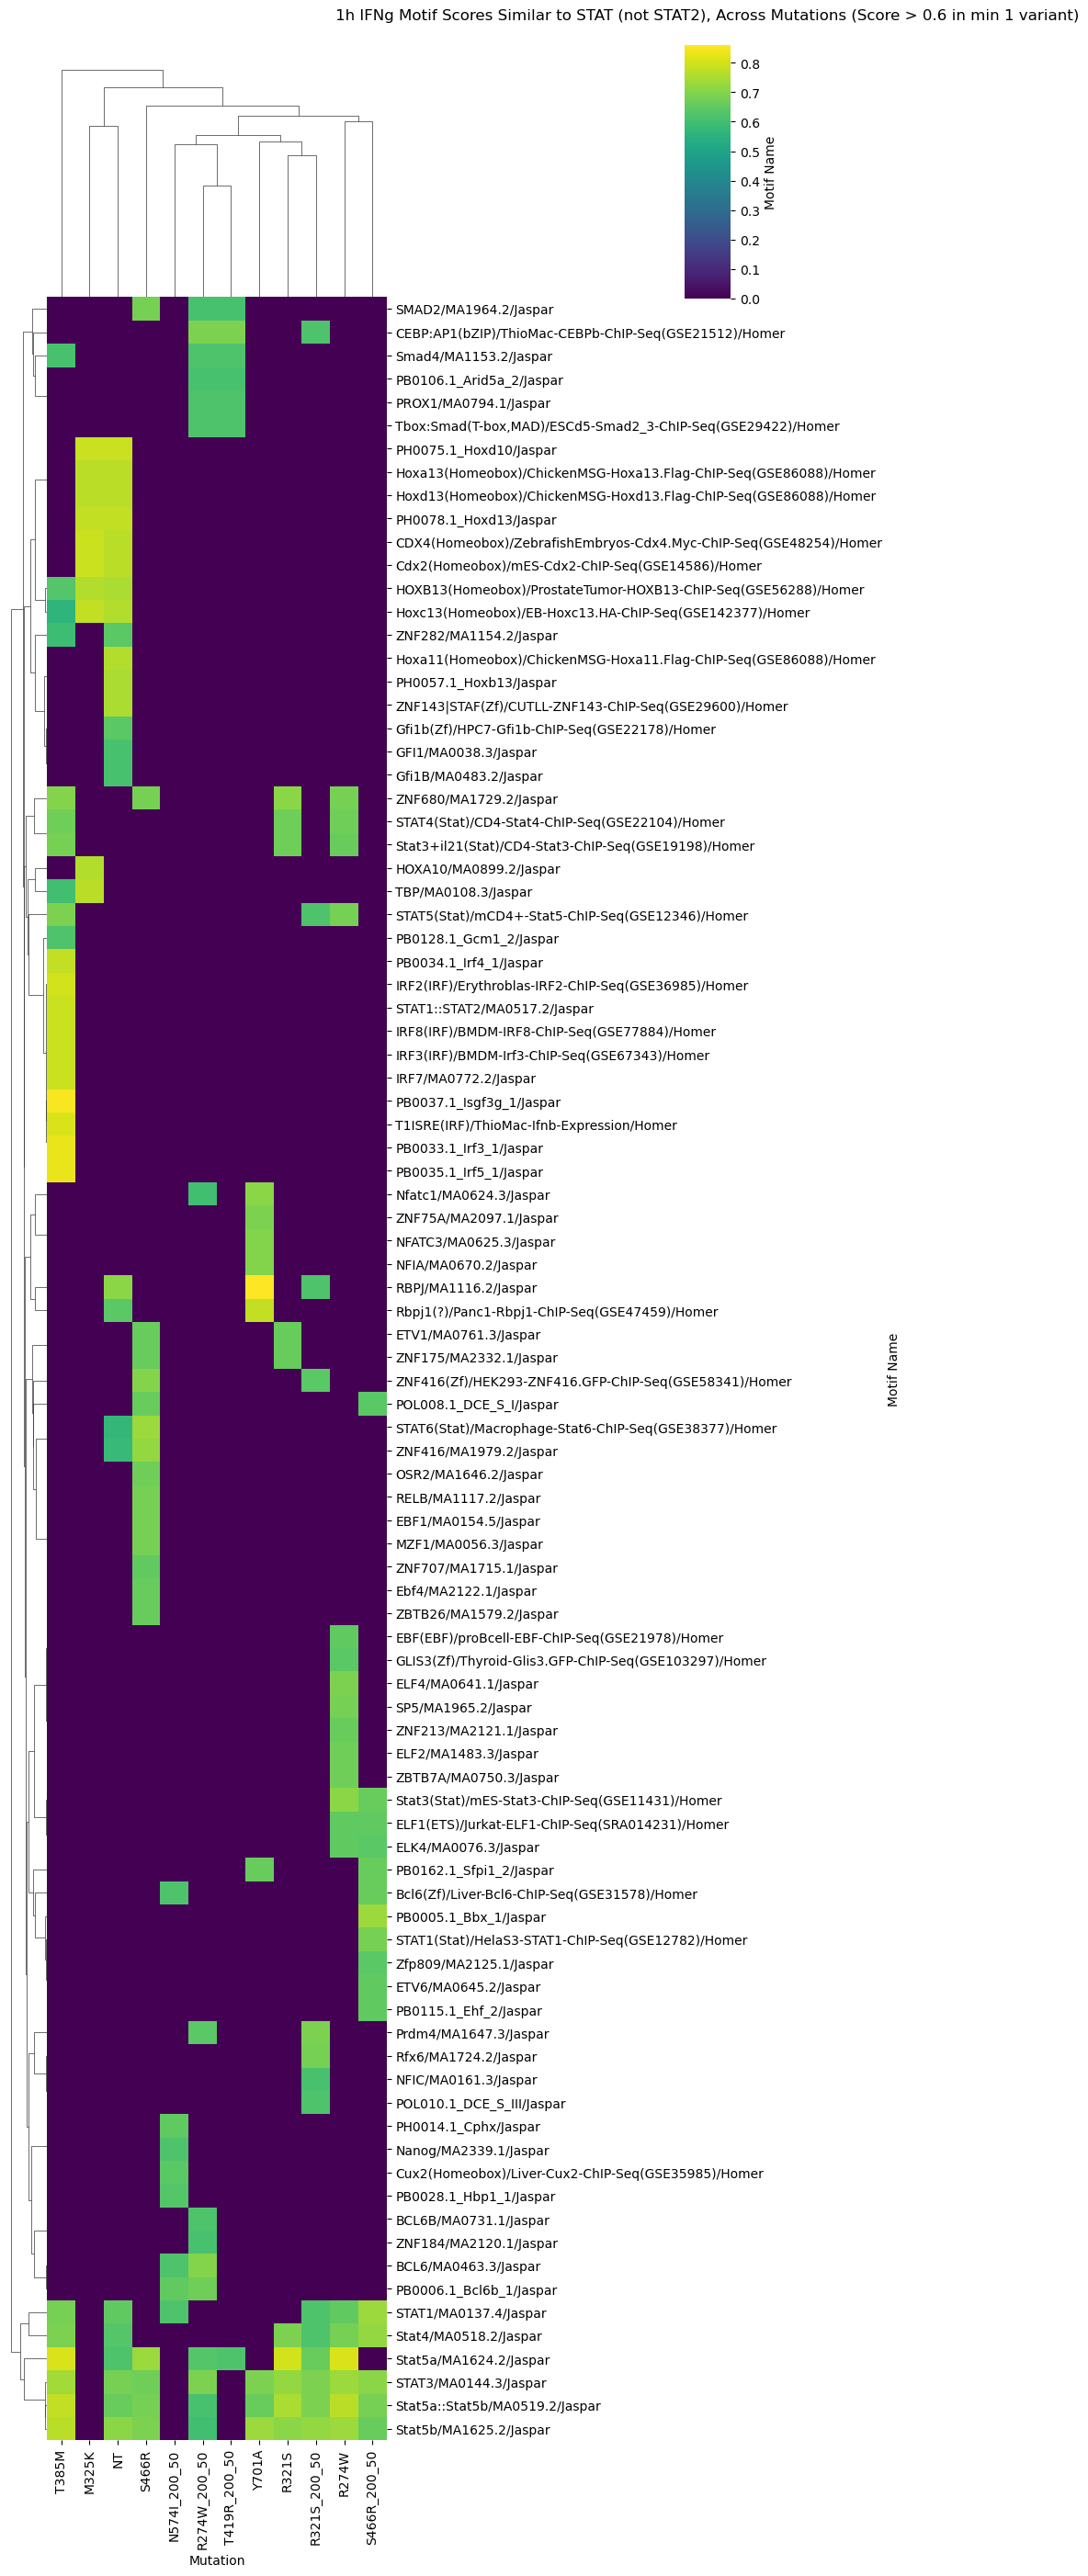

In [62]:
# Get unique Motif Number and Mutation combinations for STAT motifs
unique_combinations = df_denovo[df_denovo['Motif Name'].str.contains(r'STAT(?!2)', case=False, na=False, regex=True)][['Motif Number', 'Mutation']].drop_duplicates()

# Filter df_denovo to include only rows matching unique_combinations
df_filtered = df_denovo[df_denovo.set_index(['Motif Number', 'Mutation']).index.isin(unique_combinations.set_index(['Motif Number', 'Mutation']).index)]

pivot_df = df_filtered.pivot_table(
    values='Score',
    index='Motif Name',
    columns='Mutation',
    aggfunc='max'  # Use max score for duplicates
)

pivot_df = pivot_df[pivot_df.max(axis=1) > 0.6]

# Check for non-finite values (NaN or inf)
if not pivot_df.apply(lambda x: np.isfinite(x)).all().all():
    print("Non-finite values detected in pivot_df. Filling NaN with 0.")
    pivot_df = pivot_df.fillna(0)  # Replace NaN with 0
    # Check for infinite values
    if not pivot_df.apply(lambda x: np.isfinite(x)).all().all():
        print("Infinite values detected in pivot_df. Problematic rows:")
        print(pivot_df[~pivot_df.apply(lambda x: np.isfinite(x)).all(axis=1)])
        exit(1)

# Generate clustermap with hierarchical clustering
g= sns.clustermap(
    pivot_df,
    cmap='viridis',  # Color map for scores
    cbar_kws={'label': 'Score'},  # Colorbar label
    figsize=(10, max(10, len(pivot_df) * 0.3)),  # Scale height with number of motifs
    dendrogram_ratio=0.1,  # Size of dendrograms
    cbar_pos=(0.75, 0.90, 0.05, 0.1)  # Position of colorbar
)

# Customize plot
plt.title('1h IFNg Motif Scores Similar to STAT (not STAT2), Across Mutations (Score > 0.6 in min 1 variant)', pad=20)
plt.ylabel('Motif Name')
plt.setp(g.ax_heatmap.get_xticklabels(), rotation=90, ha='center')

plt.show()

Non-finite values detected in pivot_df. Filling NaN with 0.


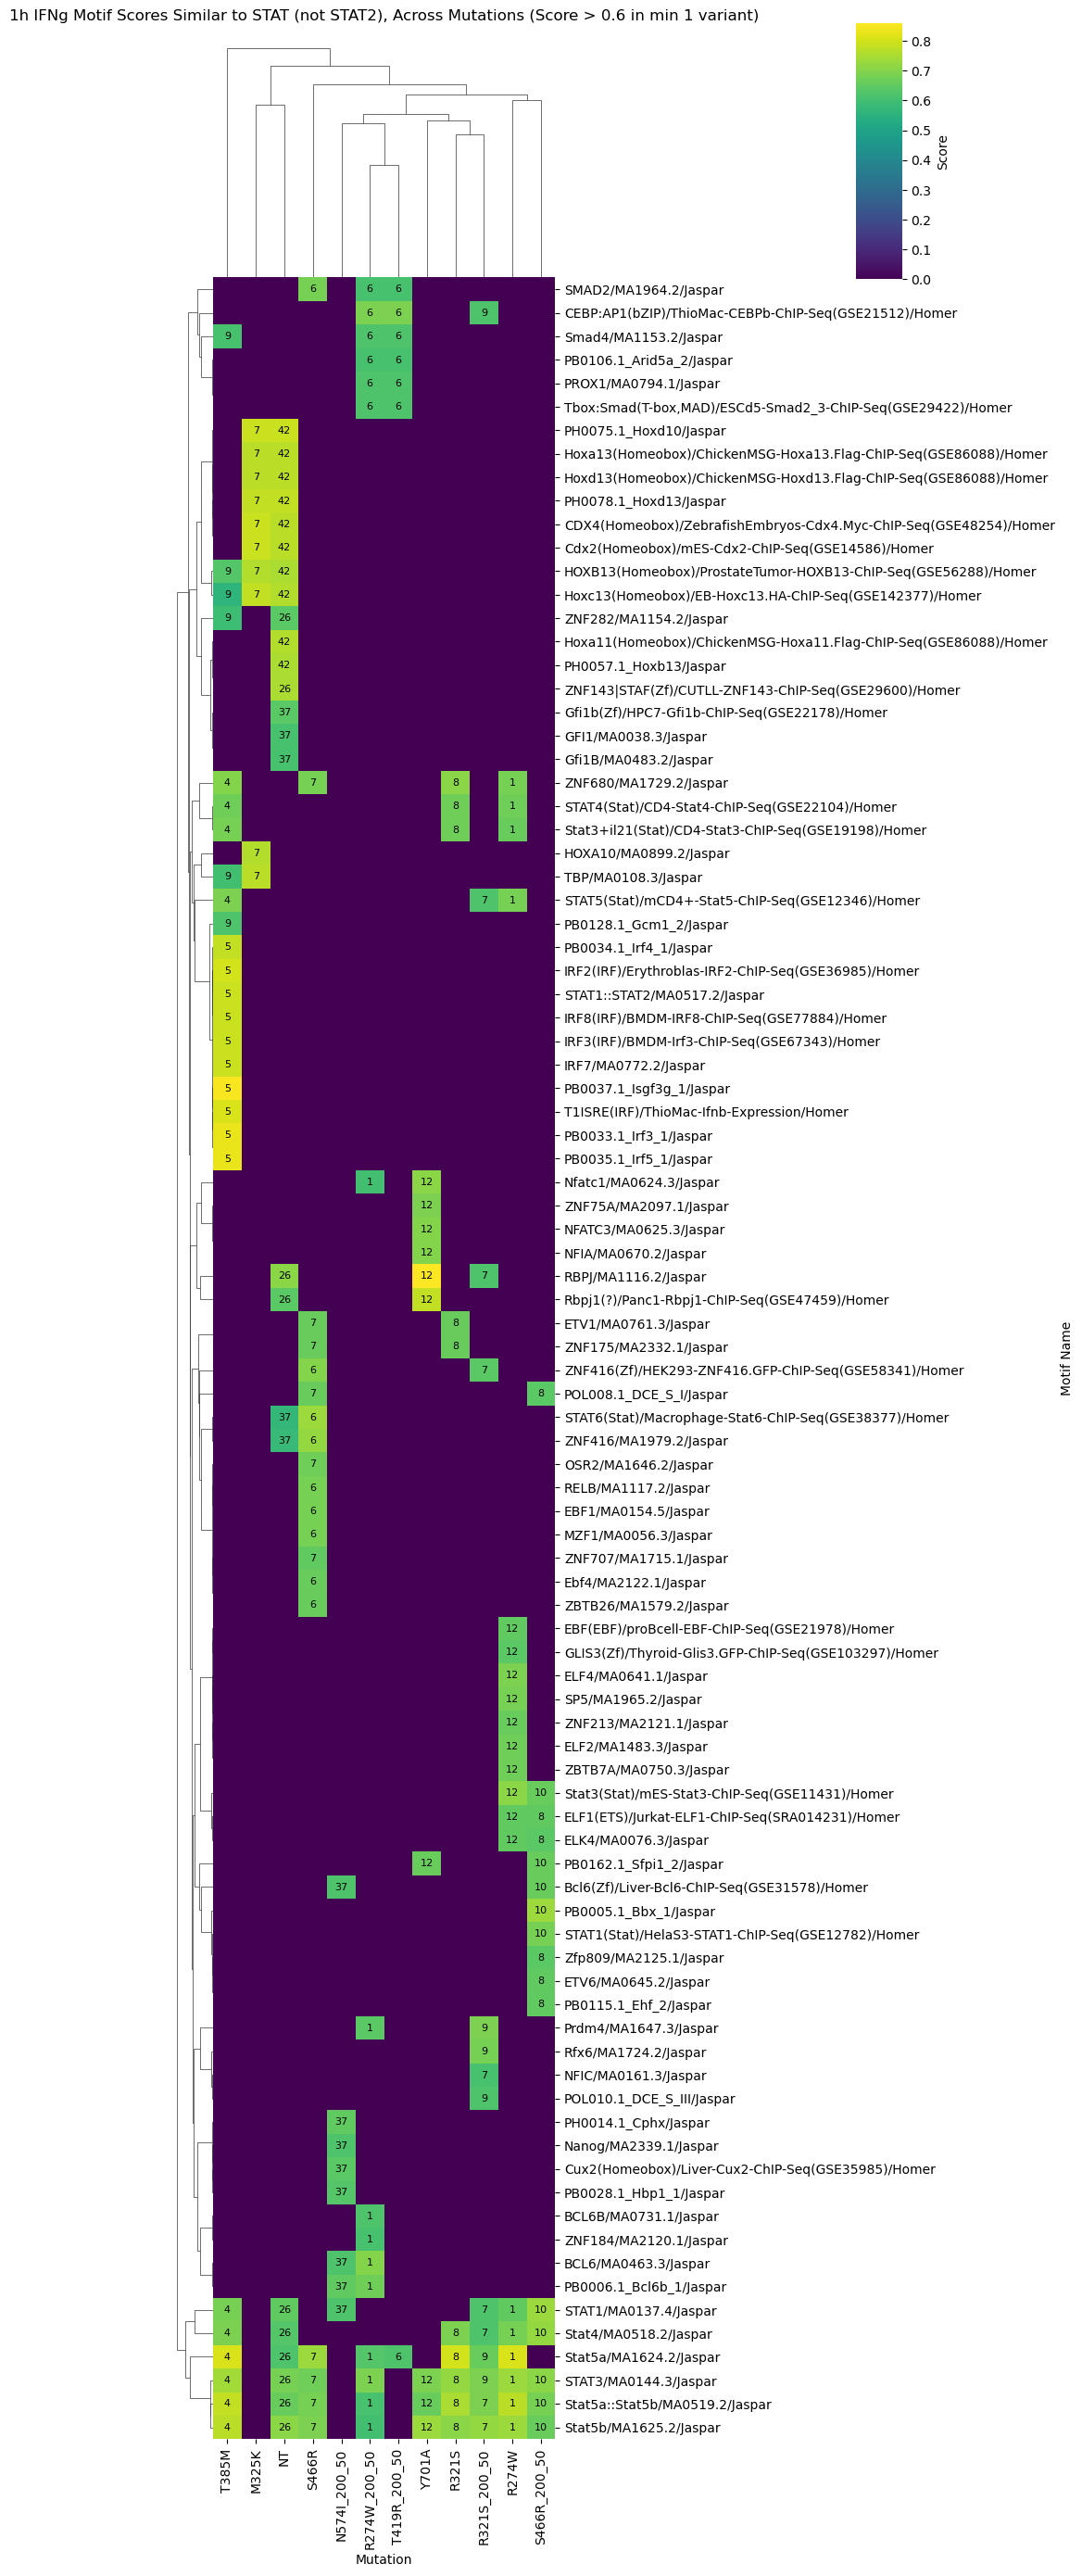

In [63]:
# Get unique Motif Number and Mutation combinations for STAT motifs
unique_combinations = df_denovo[df_denovo['Motif Name'].str.contains(r'STAT(?!2)', case=False, na=False, regex=True)][['Motif Number', 'Mutation']].drop_duplicates()

# Filter df_denovo to include only rows matching unique_combinations
df_filtered = df_denovo[df_denovo.set_index(['Motif Number', 'Mutation']).index.isin(unique_combinations.set_index(['Motif Number', 'Mutation']).index)]

all_mutations = df_denovo['Mutation'].unique()

# Create pivot table for scores
pivot_df = df_filtered.pivot_table(
    values='Score',
    index='Motif Name',
    columns='Mutation',
    aggfunc='max'  # Use max score for duplicates
)

# Create pivot table for motif numbers (for annotations)
pivot_motif_numbers = df_filtered.pivot_table(
    values='Motif Number',
    index='Motif Name',
    columns='Mutation',
    aggfunc='first'  # Take the first Motif Number for duplicates
)

# Filter rows where max score across mutations is > 0.6
pivot_df = pivot_df[pivot_df.max(axis=1) > 0.6]

# Align pivot_motif_numbers with pivot_df to ensure same index and columns
pivot_motif_numbers = pivot_motif_numbers.loc[pivot_df.index, pivot_df.columns]

# Check for non-finite values (NaN or inf) in pivot_df
if not pivot_df.apply(lambda x: np.isfinite(x)).all().all():
    print("Non-finite values detected in pivot_df. Filling NaN with 0.")
    pivot_df = pivot_df.fillna(0)  # Replace NaN with 0
    # Check for infinite values
    if not pivot_df.apply(lambda x: np.isfinite(x)).all().all():
        print("Infinite values detected in pivot_df. Problematic rows:")
        print(pivot_df[~pivot_df.apply(lambda x: np.isfinite(x)).all(axis=1)])
        exit(1)

# Generate clustermap with hierarchical clustering
g = sns.clustermap(
    pivot_df,
    cmap='viridis',  # Color map for scores
    cbar_kws={'label': 'Score'},  # Colorbar label
    figsize=(10, max(10, len(pivot_df) * 0.3)),  # Scale height with number of motifs
    dendrogram_ratio=0.1,  # Size of dendrograms
    cbar_pos=(0.75, 0.90, 0.05, 0.1)  # Position of colorbar
)

# Get the reordered indices from the clustermap
row_order = g.dendrogram_row.reordered_ind
col_order = g.dendrogram_col.reordered_ind

# Reorder pivot_df and pivot_motif_numbers to match clustermap order
pivot_df_reordered = pivot_df.iloc[row_order, col_order]
pivot_motif_numbers_reordered = pivot_motif_numbers.iloc[row_order, col_order]

# Add annotations for Motif Number
for i in range(pivot_df_reordered.shape[0]):
    for j in range(pivot_df_reordered.shape[1]):
        motif_num = pivot_motif_numbers_reordered.iloc[i, j]
        if pd.notna(motif_num):  # Only annotate if motif number exists
            g.ax_heatmap.text(
                j + 0.5,  # Center in x
                i + 0.5,  # Center in y
                f'{int(motif_num)}',  # Convert to int to avoid decimal
                ha='center',
                va='center',
                color='white' if pivot_df_reordered.iloc[i, j] < 0.5 else 'black',  # Contrast based on score
                fontsize=8
            )

# Customize plot
g.ax_heatmap.set_title('1h IFNg Motif Scores Similar to STAT (not STAT2), Across Mutations (Score > 0.6 in min 1 variant)', pad=200)
g.ax_heatmap.set_ylabel('Motif Name')
plt.setp(g.ax_heatmap.get_xticklabels(), rotation=90, ha='center')

plt.show()

Non-finite values detected in pivot_df. Filling NaN with 0.


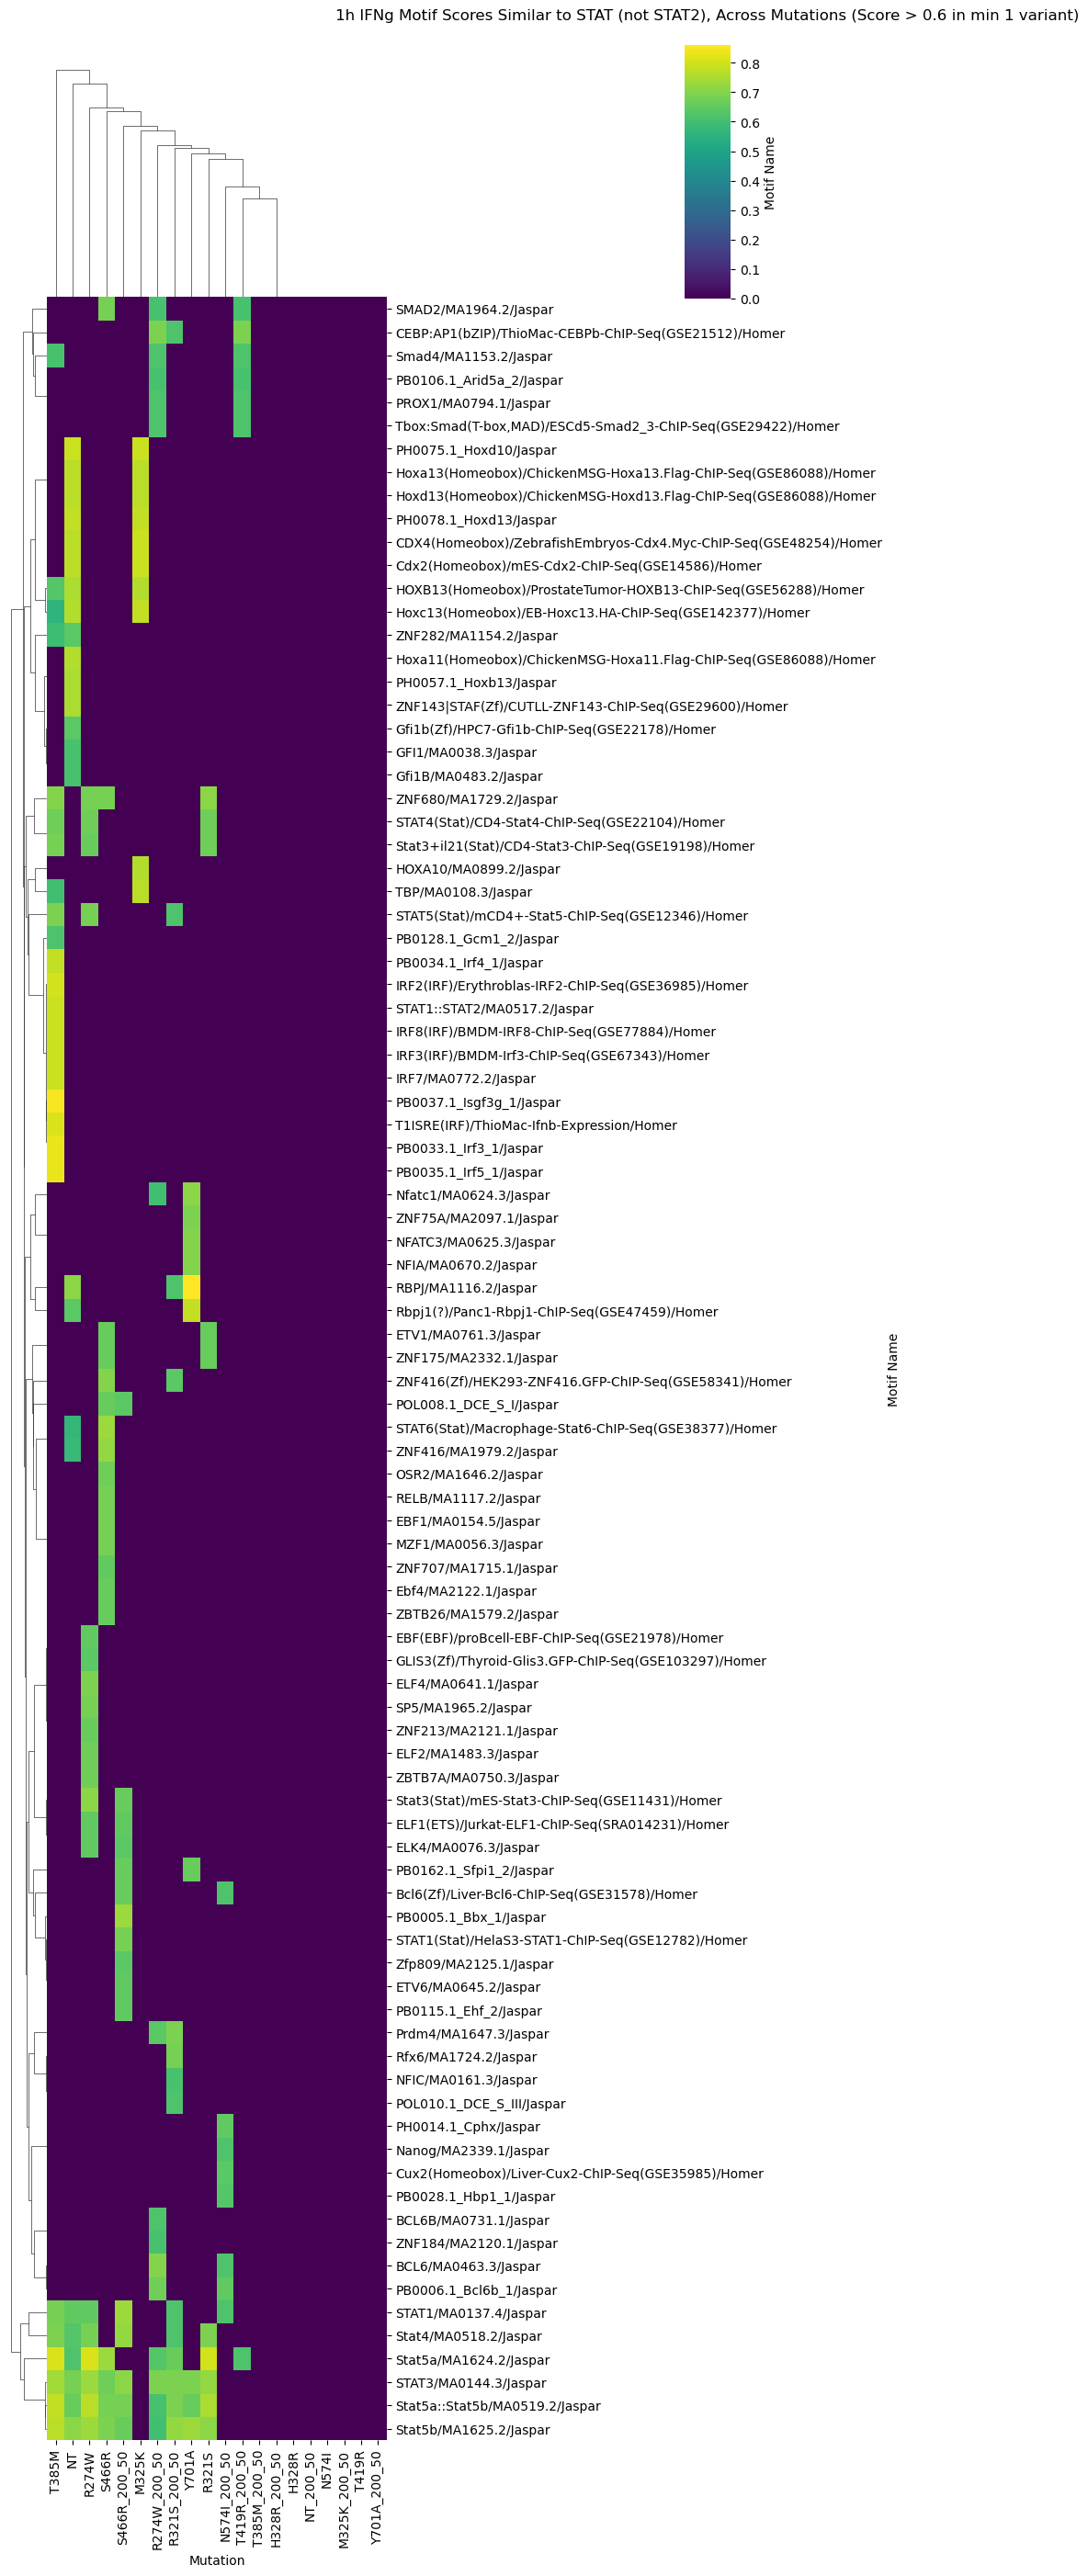

In [68]:
# Get unique Motif Number and Mutation combinations for STAT motifs
unique_combinations = df_denovo[df_denovo['Motif Name'].str.contains(r'STAT(?!2)', case=False, na=False, regex=True)][['Motif Number', 'Mutation']].drop_duplicates()

# Filter df_denovo to include only rows matching unique_combinations
df_filtered = df_denovo[df_denovo.set_index(['Motif Number', 'Mutation']).index.isin(unique_combinations.set_index(['Motif Number', 'Mutation']).index)]

all_mutations = df_denovo['Mutation'].unique()

pivot_df = df_filtered.pivot_table(
    values='Score',
    index='Motif Name',
    columns='Mutation',
    aggfunc='max'  # Use max score for duplicates
).reindex(columns=all_mutations)

pivot_df = pivot_df[pivot_df.max(axis=1) > 0.6]

# Check for non-finite values (NaN or inf)
if not pivot_df.apply(lambda x: np.isfinite(x)).all().all():
    print("Non-finite values detected in pivot_df. Filling NaN with 0.")
    pivot_df = pivot_df.fillna(0)  # Replace NaN with 0
    # Check for infinite values
    if not pivot_df.apply(lambda x: np.isfinite(x)).all().all():
        print("Infinite values detected in pivot_df. Problematic rows:")
        print(pivot_df[~pivot_df.apply(lambda x: np.isfinite(x)).all(axis=1)])
        exit(1)

# Generate clustermap with hierarchical clustering
g= sns.clustermap(
    pivot_df,
    cmap='viridis',  # Color map for scores
    cbar_kws={'label': 'Score'},  # Colorbar label
    figsize=(10, max(10, len(pivot_df) * 0.3)),  # Scale height with number of motifs
    dendrogram_ratio=0.1,  # Size of dendrograms
    cbar_pos=(0.75, 0.90, 0.05, 0.1)  # Position of colorbar
)

# Customize plot
plt.title('1h IFNg Motif Scores Similar to STAT (not STAT2), Across Mutations (Score > 0.6 in min 1 variant)', pad=20)
plt.ylabel('Motif Name')
plt.setp(g.ax_heatmap.get_xticklabels(), rotation=90, ha='center')

plt.show()

In [65]:
# Group by Mutation and Motif Name to get counts
counts = df_denovo.groupby(['Mutation', 'Motif Name']).size().reset_index(name='Count')

# Filter for Mutation and Motif Name pairs with Count > 1
valid_pairs = counts[counts['Count'] > 1][['Mutation', 'Motif Name']]

# Filter original df_denovo to keep only rows matching valid pairs
df_filtered = df_denovo.merge(valid_pairs, on=['Mutation', 'Motif Name'], how='inner')

# Print the filtered DataFrame with all original columns
df_filtered.head(20)
df_filtered.to_csv("denovo_motifs_repeat.csv", index=False)